# Handling Class Imbalance in Network Intrusion Detection
### Adaptive cost-sensitive XGBoost on CICIDS2017

Network intrusion datasets are extremely lopsided: in CICIDS2017 more than 80% of the flows are benign, and
some attack types (XSS, brute-force web attacks, bots) make up well under 1% of the data. A classifier can hit
99.9% accuracy here and still miss most of the rare attacks, so accuracy is the wrong thing to look at.

This notebook builds a 12-class intrusion detector and focuses on **macro F1** (every class counts equally).
The main idea I test is **ACS-XGBoost**: instead of hand-picking class weights (for example "XSS x5, Bot x3"),
the weights are generated automatically from two signals, how rare a class is and how badly a first-pass model
does on it. The result is compared against LightGBM and four XGBoost baselines, tuned with Optuna, checked with
5-fold cross-validation and explained with SHAP.

| Step | What happens |
|---|---|
| 1. Data | Load 8 CSVs, clean, stratified 60/20/20 split, leakage-safe feature selection |
| 2. Baselines | LightGBM + 4 XGBoost variants (balanced weights, SMOTE, two hand-tuned weight sets) |
| 3. ACS-XGBoost | Adaptive weights, Optuna search (50 trials), final model, SHAP |
| 4. Robustness | 5-fold CV, learning curve, paired Wilcoxon test against plain XGBoost |

**Headline result:** ACS-XGBoost reaches **91.5% macro F1** on the held-out test set. That beats LightGBM and
three of the four XGBoost baselines, but it does *not* beat the hand-tuned V4 baseline (91.6%), and in
cross-validation the difference to plain XGBoost is not statistically significant (see the last section).
I kept those results in rather than tidying them away.

**Contents:** [1. Data](#1.-Data) | [2. Baselines](#2.-Baseline-models) | [3. ACS-XGBoost](#3.-ACS-XGBoost) | [4. Robustness](#4.-Robustness-checks) | [5. Takeaways](#5.-Takeaways-and-limitations)

> Run on a Kaggle notebook with a Tesla P100. The two slowest steps were the Optuna search (about 43 min)
> and the SMOTE-based model (about 8 min).

## Setup

In [1]:
import gc
import glob
import os
import platform
import subprocess
import time
import warnings

import joblib
import kagglehub
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import psutil
import seaborn as sns
import shap
import xgboost as xgb
from imblearn.over_sampling import SMOTE
from scipy.stats import wilcoxon
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, auc, average_precision_score, balanced_accuracy_score,
                             classification_report, cohen_kappa_score, confusion_matrix, f1_score,
                             matthews_corrcoef, precision_recall_curve, precision_score, recall_score,
                             roc_curve)
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit, train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid", palette="Set2")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

os.makedirs("final_model/plots", exist_ok=True)
os.makedirs("final_model/tables", exist_ok=True)

---
## 1. Data

**Dataset:** [CICIDS2017](https://www.unb.ca/cic/datasets/ids-2017.html) (Canadian Institute for Cybersecurity),
the `MachineLearningCVE` flow-feature CSVs, pulled through `kagglehub`. Each row is one network flow with 78
numeric features and a label.

### 1.1 Load

In [2]:
path = kagglehub.dataset_download("mdalamintalukder/cicids2017")
data_dir = os.path.join(path, "MachineLearningCVE")
csv_files = glob.glob(os.path.join(data_dir, "*.csv"))

if not csv_files:
    raise FileNotFoundError(f"No CSV files found in {data_dir}")

print(f"\nFound {len(csv_files)} CSV files in {data_dir}:")
for f in csv_files:
    print(f"  {os.path.basename(f):<65} {os.path.getsize(f) / 1e6:.1f} MB")

frames = []
for f in csv_files:
    part = pd.read_csv(f, low_memory=False)
    frames.append(part)
    print(f"  Loaded {os.path.basename(f)} -> {part.shape}")

df = pd.concat(frames, ignore_index=True)
df.columns = df.columns.str.strip()      # some headers have stray spaces
print("Final shape:", df.shape)

Found 8 CSV files in /kaggle/input/datasets/mdalamintalukder/cicids2017/MachineLearningCVE:
  Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv              76.9 MB
  Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv            52.0 MB
  Tuesday-WorkingHours.pcap_ISCX.csv                                135.1 MB
  Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv                  77.1 MB
  Monday-WorkingHours.pcap_ISCX.csv                                 176.9 MB
  Friday-WorkingHours-Morning.pcap_ISCX.csv                         58.3 MB
  Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv       83.1 MB
  Wednesday-workingHours.pcap_ISCX.csv                              225.2 MB
  Loaded Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv -> (286467, 79)
  Loaded Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv -> (170366, 79)
  Loaded Tuesday-WorkingHours.pcap_ISCX.csv -> (445909, 79)
  Loaded Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv -> (225745, 79)
  Loa

### 1.2 First look at the raw data

The imbalance is severe. BENIGN is ~80% of all rows while XSS has 652 flows, and Heartbleed, SQL injection and
Infiltration have fewer than 40 each. The raw data also has duplicates, `NaN`s and `inf` values to deal with.

=== Class Distribution (raw, before any cleaning) ===
Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


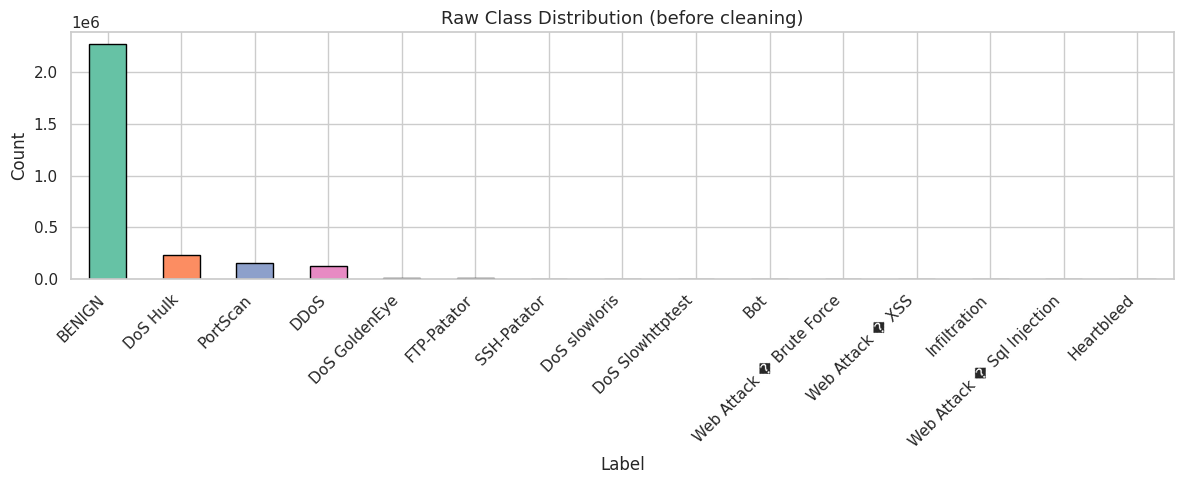

Missing values (raw): 1,358
Infinity values (raw): 4,376
Duplicate rows (raw) : 308,381 (10.89%)


In [3]:
label_col = "Label"

print("\n=== Class Distribution (raw, before any cleaning) ===")
label_counts = df[label_col].value_counts()
print(label_counts)

plt.figure(figsize=(12, 5))
label_counts.plot(kind='bar', color=sns.color_palette('Set2', len(label_counts)), edgecolor='black')
plt.title('Raw Class Distribution (before cleaning)', fontsize=13)
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('final_model/plots/c1_01_raw_class_distribution.png', dpi=150)
plt.show()

num_cols_raw = df.select_dtypes(include=[np.number]).columns
n_dup = df.duplicated().sum()
print(f"\nMissing values (raw): {df.isnull().sum().sum():,}")
print(f"Infinity values (raw): {np.isinf(df[num_cols_raw]).sum().sum():,}")
print(f"Duplicate rows (raw) : {n_dup:,} ({n_dup / len(df) * 100:.2f}%)")

### 1.3 Cleaning

Only row-level cleaning happens here. Anything that *learns from the data* (variance filter, correlation
filter, imputation) waits until after the split, so that validation and test rows cannot influence it.

- **Duplicates** are dropped (about 11% of rows).
- **Infinity** values come from divide-by-zero in some flow-rate features of CICIDS2017. They are turned into
  `NaN` and imputed later.
- **Heartbleed, SQL Injection and Infiltration** are removed. With 11, 21 and 36 samples there is nothing a
  model can reliably learn, and a 20% test split would hold only a handful of them.
  This is decided from the class counts only, so it does not leak anything from the split.

In [4]:
# 1) exact duplicates
before = len(df)
df_clean = df.drop_duplicates()
print(f"Duplicates removed : {before - len(df_clean):,} ({before:,} -> {len(df_clean):,} rows)")

# 2) inf -> NaN
num_cols = df_clean.select_dtypes(include=[np.number]).columns
inf_before = np.isinf(df_clean[num_cols]).sum().sum()
df_clean = df_clean.copy()
df_clean[num_cols] = df_clean[num_cols].replace([np.inf, -np.inf], np.nan)
print(f"Infinity -> NaN     : {inf_before:,} values converted")

# 3) classes with too few samples
rare_keywords = ["Heartbleed", "Sql Injection", "Infiltration"]
rare_classes = [l for l in df_clean[label_col].unique() if any(k in l for k in rare_keywords)]
print(f"\nDropping unlearnable classes: {rare_classes}")
for cls in rare_classes:
    print(f"    - {cls}: {(df_clean[label_col] == cls).sum()} samples removed")

before = len(df_clean)
df_model = df_clean[~df_clean[label_col].isin(rare_classes)].copy()
print(f"    Rows: {before:,} -> {len(df_model):,}")
print(f"    Classes remaining: {df_model[label_col].nunique()}")
print(f"\nCleaning complete. Final shape before split: {df_model.shape}")

Duplicates removed : 308,381 (2,830,743 -> 2,522,362 rows)
Infinity -> NaN     : 2,775 values converted

Dropping unlearnable classes: ['Web Attack � Sql Injection', 'Infiltration', 'Heartbleed']
    - Web Attack � Sql Injection: 21 samples removed
    - Infiltration: 36 samples removed
    - Heartbleed: 11 samples removed
    Rows: 2,522,362 -> 2,522,294
    Classes remaining: 12

Cleaning complete. Final shape before split: (2522294, 79)


### 1.4 Encode labels and split

Stratified 60/20/20 split into train / validation / test. Validation is used for early stopping and for the
Optuna search; the test set is only touched for final scores.

In [5]:
le = LabelEncoder()
df_model["Label_encoded"] = le.fit_transform(df_model[label_col])

print("=== Label Encoding Map ===")
for i, cls in enumerate(le.classes_):
    n = (df_model["Label_encoded"] == i).sum()
    print(f"  {i:2d} -> {cls:<35} ({n:,} samples)")

X = df_model.drop(columns=[label_col, "Label_encoded"])
y = df_model["Label_encoded"]

print(f"\nFeature matrix X : {X.shape}")
print(f"Target vector y  : {y.shape}")
print(f"Features         : {X.shape[1]}")
print(f"Classes          : {y.nunique()}")

=== Label Encoding Map ===
   0 -> BENIGN                              (2,096,484 samples)
   1 -> Bot                                 (1,953 samples)
   2 -> DDoS                                (128,016 samples)
   3 -> DoS GoldenEye                       (10,286 samples)
   4 -> DoS Hulk                            (172,849 samples)
   5 -> DoS Slowhttptest                    (5,228 samples)
   6 -> DoS slowloris                       (5,385 samples)
   7 -> FTP-Patator                         (5,933 samples)
   8 -> PortScan                            (90,819 samples)
   9 -> SSH-Patator                         (3,219 samples)
  10 -> Web Attack � Brute Force            (1,470 samples)
  11 -> Web Attack � XSS                    (652 samples)

Feature matrix X : (2522294, 78)
Target vector y  : (2522294,)
Features         : 78
Classes          : 12


In [6]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=RANDOM_STATE, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=RANDOM_STATE, stratify=y_temp)

print("\n=== Stratified 60/20/20 Split ===")
for name, part in [("Train", X_train), ("Val", X_val), ("Test", X_test)]:
    print(f"  {name:<5} : {len(part):,} rows ({len(part) / len(X) * 100:.1f}%)")

print("\n=== Class Ratio Check (should be near-identical across splits) ===")
print(f"{'Class':<35} {'Train%':>8} {'Val%':>8} {'Test%':>8}")
for cls in sorted(y.unique()):
    tr = (y_train == cls).mean() * 100
    vl = (y_val == cls).mean() * 100
    te = (y_test == cls).mean() * 100
    print(f"  {le.classes_[cls]:<33} {tr:>7.2f}% {vl:>7.2f}% {te:>7.2f}%")

=== Stratified 60/20/20 Split ===
  Train : 1,513,376 rows (60.0%)
  Val   : 504,459 rows (20.0%)
  Test  : 504,459 rows (20.0%)

=== Class Ratio Check (should be near-identical across splits) ===
Class                                 Train%     Val%    Test%
  BENIGN                              83.12%   83.12%   83.12%
  Bot                                  0.08%    0.08%    0.08%
  DDoS                                 5.08%    5.08%    5.08%
  DoS GoldenEye                        0.41%    0.41%    0.41%
  DoS Hulk                             6.85%    6.85%    6.85%
  DoS Slowhttptest                     0.21%    0.21%    0.21%
  DoS slowloris                        0.21%    0.21%    0.21%
  FTP-Patator                          0.24%    0.24%    0.24%
  PortScan                             3.60%    3.60%    3.60%
  SSH-Patator                          0.13%    0.13%    0.13%
  Web Attack � Brute Force             0.06%    0.06%    0.06%
  Web Attack � XSS                     0.03%   

### 1.5 Feature selection (training split only)

Two filters, both computed on `X_train` and then applied unchanged to validation and test:

1. **Zero-variance columns:** constant in the training data, so no information.
2. **Highly correlated columns (|r| > 0.95):** near-duplicates that slow training and add noise.

Doing this *before* the split would let validation/test rows decide which columns survive, which is a quiet
form of leakage.

In [7]:
# zero-variance columns
num_train = X_train.select_dtypes(include=[np.number])
zero_var_cols = num_train.columns[num_train.var() == 0].tolist()
print(f"Zero-variance columns (from X_train) : {len(zero_var_cols)}")
for c in zero_var_cols:
    print(f"    - {c}")

X_train = X_train.drop(columns=zero_var_cols)
X_val = X_val.drop(columns=zero_var_cols)
X_test = X_test.drop(columns=zero_var_cols)

# highly correlated pairs
print("\nCalculating correlations (X_train only) to find near-duplicate columns...")
corr_matrix = X_train.select_dtypes(include=[np.number]).corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_pairs = [(col, row, upper.loc[row, col])
                   for col in upper.columns for row in upper.index
                   if upper.loc[row, col] > 0.95]
high_corr_df = pd.DataFrame(high_corr_pairs, columns=["Feature 1", "Feature 2", "Correlation"])
high_corr_df = high_corr_df.sort_values("Correlation", ascending=False)
print(f"    Found {len(high_corr_df)} highly correlated pairs (>0.95)")

to_drop = set()
for _, pair in high_corr_df.iterrows():
    if pair["Feature 1"] not in to_drop:
        to_drop.add(pair["Feature 2"])
to_drop = [c for c in to_drop if c in X_train.columns]

X_train = X_train.drop(columns=to_drop)
X_val = X_val.drop(columns=to_drop)
X_test = X_test.drop(columns=to_drop)

print(f"    Dropped {len(to_drop)} redundant columns (same columns removed from X_train, X_val, X_test)")
print(f"    Shape now -> Train: {X_train.shape}  Val: {X_val.shape}  Test: {X_test.shape}")

Zero-variance columns (from X_train) : 8
    - Bwd PSH Flags
    - Bwd URG Flags
    - Fwd Avg Bytes/Bulk
    - Fwd Avg Packets/Bulk
    - Fwd Avg Bulk Rate
    - Bwd Avg Bytes/Bulk
    - Bwd Avg Packets/Bulk
    - Bwd Avg Bulk Rate

Calculating correlations (X_train only) to find near-duplicate columns...
    Found 39 highly correlated pairs (>0.95)
    Dropped 22 redundant columns (same columns removed from X_train, X_val, X_test)
    Shape now -> Train: (1513376, 48)  Val: (504459, 48)  Test: (504459, 48)


### 1.6 Impute missing values

The `inf` -> `NaN` values plus the original `NaN`s are filled with the **median of the training split**, and
the same medians are reused for validation and test.

In [8]:
num_features = X_train.select_dtypes(include=[np.number]).columns

print("Missing values before fill:")
print(f"  X_train: {X_train.isnull().sum().sum():,}")
print(f"  X_val  : {X_val.isnull().sum().sum():,}")
print(f"  X_test : {X_test.isnull().sum().sum():,}")

train_medians = X_train[num_features].median()
X_train[num_features] = X_train[num_features].fillna(train_medians)
X_val[num_features] = X_val[num_features].fillna(train_medians)
X_test[num_features] = X_test[num_features].fillna(train_medians)

print("\nMissing values after fill:")
print(f"  X_train: {X_train.isnull().sum().sum()}")
print(f"  X_val  : {X_val.isnull().sum().sum()}")
print(f"  X_test : {X_test.isnull().sum().sum()}")

Missing values before fill:
  X_train: 945
  X_val  : 313
  X_test : 306

Missing values after fill:
  X_train: 0
  X_val  : 0
  X_test : 0


Save everything so the later sections can be re-run without repeating the preprocessing.

In [9]:
X_train.to_parquet("final_model/X_train.parquet")
X_val.to_parquet("final_model/X_val.parquet")
X_test.to_parquet("final_model/X_test.parquet")
y_train.to_frame("y").to_parquet("final_model/y_train.parquet")
y_val.to_frame("y").to_parquet("final_model/y_val.parquet")
y_test.to_frame("y").to_parquet("final_model/y_test.parquet")

joblib.dump(le, "final_model/label_encoder.pkl")
train_medians.to_json("final_model/train_medians.json")
pd.Series(X_train.columns.tolist()).to_csv("final_model/feature_columns.csv", index=False)
print("Saved splits, label encoder, train medians and feature list to final_model/")

Saved splits, label encoder, train medians and feature list to final_model/


### 1.7 Exploratory plots

These run on a 50,000-row stratified sample of the **training** set, which looks the same as the full set at
this scale and is much faster to plot.

In [10]:
sss = StratifiedShuffleSplit(n_splits=1, train_size=50000, random_state=RANDOM_STATE)
idx, _ = next(sss.split(X_train, y_train))
X_eda = X_train.iloc[idx].copy()
y_eda = y_train.iloc[idx].copy()
print(f"EDA sample size: {len(X_eda):,} rows (from training set only)")

EDA sample size: 50,000 rows (from training set only)


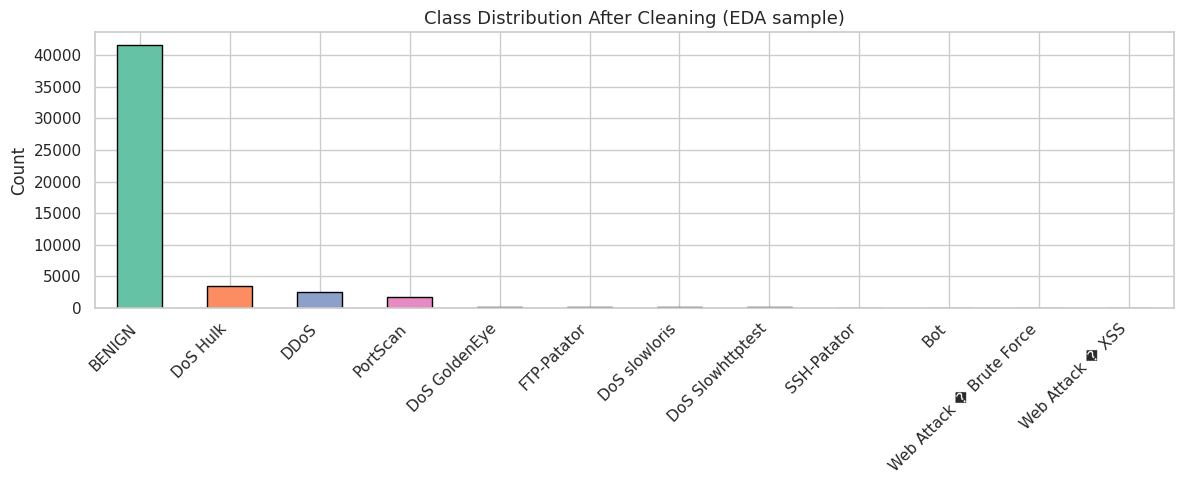

In [11]:
plt.figure(figsize=(12, 5))
class_counts_eda = pd.Series([le.classes_[i] for i in y_eda]).value_counts()
class_counts_eda.plot(kind='bar', color=sns.color_palette('Set2', len(class_counts_eda)), edgecolor='black')
plt.title('Class Distribution After Cleaning (EDA sample)', fontsize=13)
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('final_model/plots/c1_02_clean_class_distribution.png', dpi=150)
plt.show()

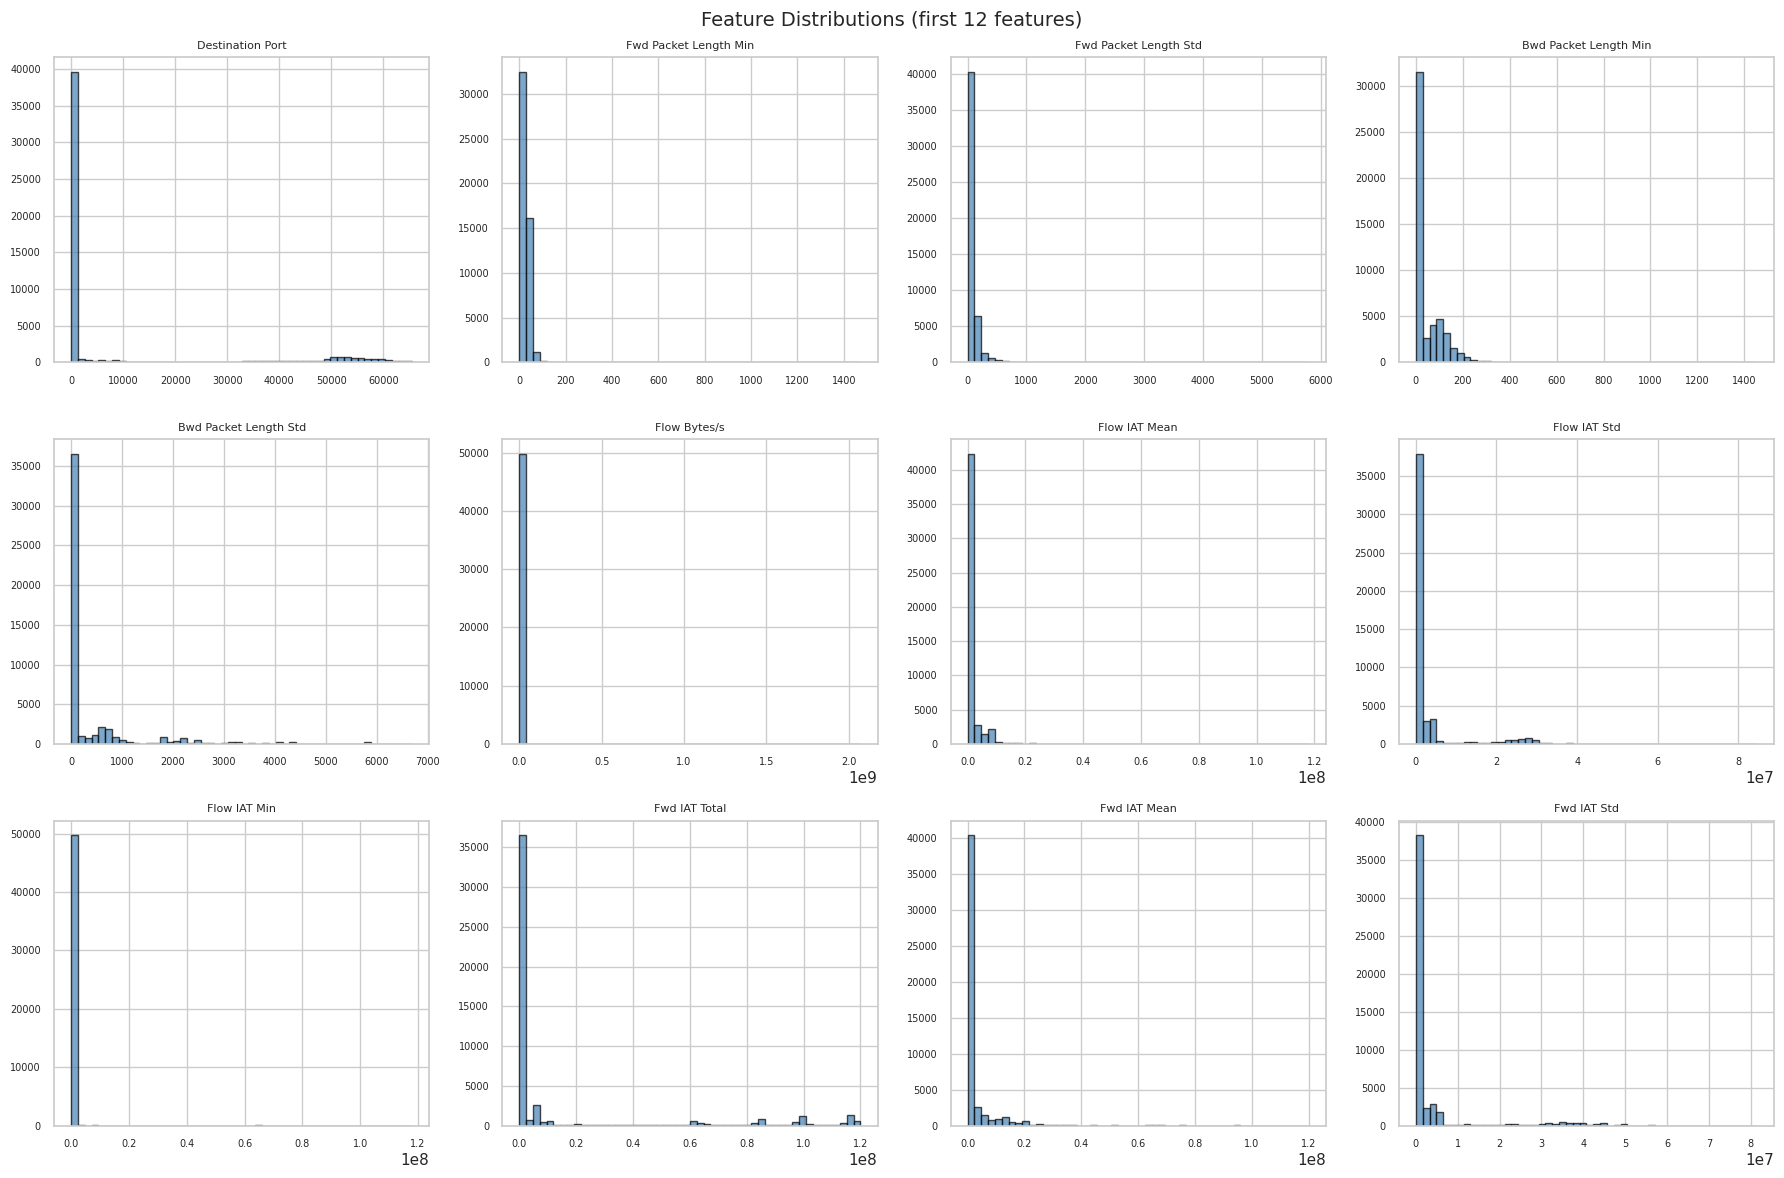

In [12]:
numeric_eda = X_eda.select_dtypes(include=[np.number]).columns[:12]
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
axes = axes.flatten()
for i, col in enumerate(numeric_eda):
    axes[i].hist(X_eda[col].dropna(), bins=50, color='steelblue', edgecolor='black', alpha=0.7)
    axes[i].set_title(col, fontsize=8)
    axes[i].tick_params(labelsize=7)
plt.suptitle('Feature Distributions (first 12 features)', fontsize=14)
plt.tight_layout()
plt.savefig('final_model/plots/c1_03_feature_distributions.png', dpi=150)
plt.show()

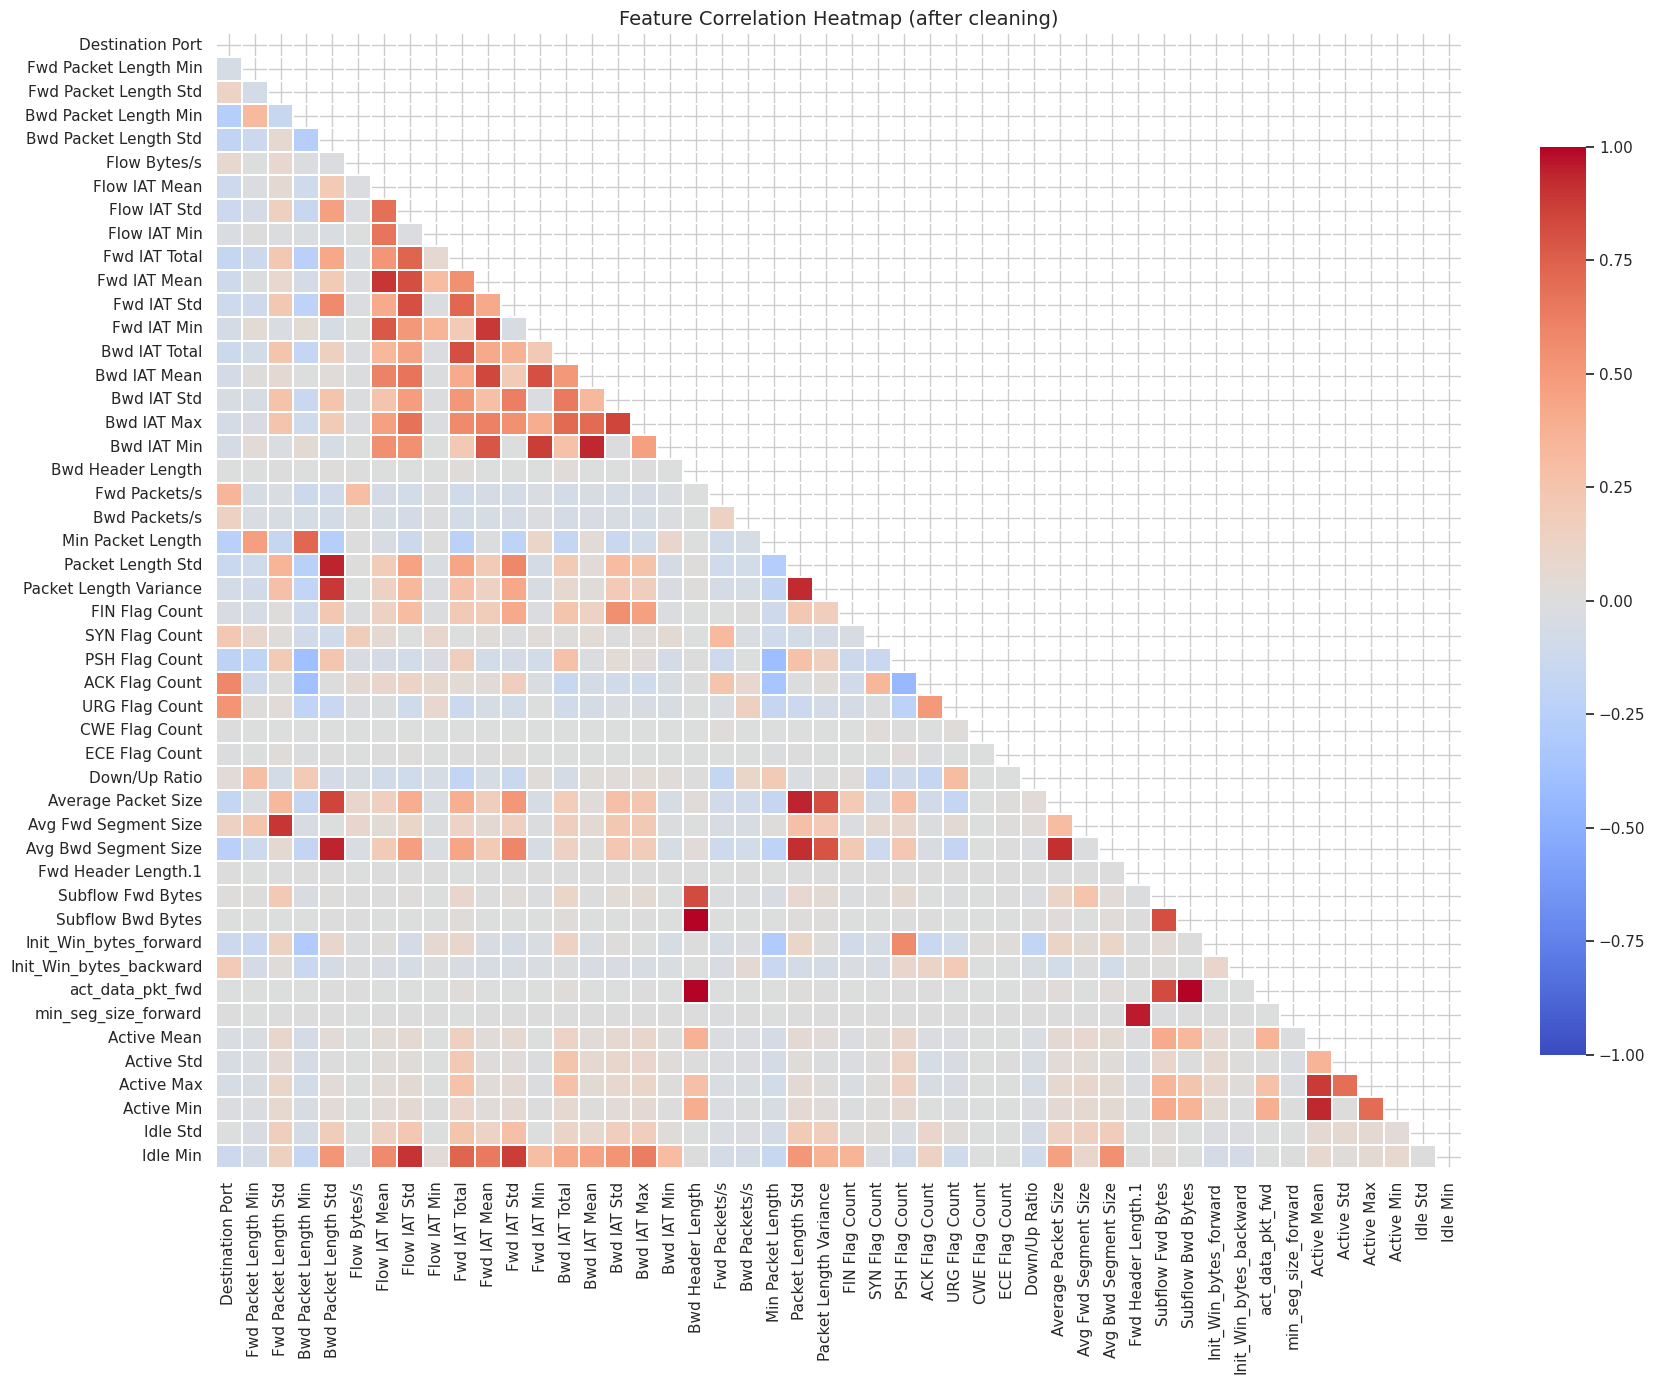

In [13]:
plt.figure(figsize=(18, 14))
corr_eda = X_eda.corr()
mask = np.triu(np.ones_like(corr_eda, dtype=bool))
sns.heatmap(corr_eda, mask=mask, cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.3, cbar_kws={'shrink': 0.8})
plt.title('Feature Correlation Heatmap (after cleaning)', fontsize=14)
plt.tight_layout()
plt.savefig('final_model/plots/c1_04_correlation_heatmap.png', dpi=150)
plt.show()

A quick random forest, only to get a rough feeling for which features carry signal (this is not the final model).

Training a quick Random Forest just to see which features matter most...


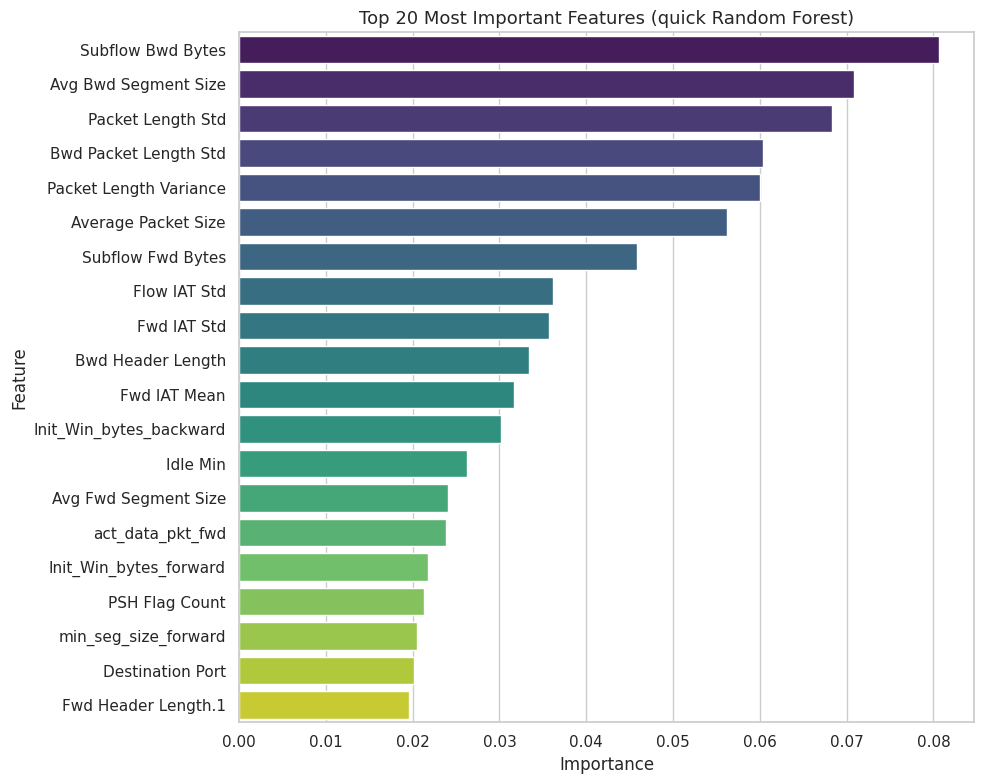

Top 10 features:
               Feature  Importance
     Subflow Bwd Bytes      0.0806
  Avg Bwd Segment Size      0.0709
     Packet Length Std      0.0683
 Bwd Packet Length Std      0.0604
Packet Length Variance      0.0601
   Average Packet Size      0.0562
     Subflow Fwd Bytes      0.0458
          Flow IAT Std      0.0362
           Fwd IAT Std      0.0357
     Bwd Header Length      0.0334


In [14]:
print("Training a quick Random Forest just to see which features matter most...")
rf_quick = RandomForestClassifier(n_estimators=50, max_depth=10, n_jobs=-1, random_state=RANDOM_STATE)
rf_quick.fit(X_eda, y_eda)
importance_df = pd.DataFrame({
    'Feature': X_eda.columns,
    'Importance': rf_quick.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(data=importance_df.head(20), x='Importance', y='Feature', palette='viridis')
plt.title('Top 20 Most Important Features (quick Random Forest)', fontsize=13)
plt.tight_layout()
plt.savefig('final_model/plots/c1_05_feature_importance.png', dpi=150)
plt.show()

print("\nTop 10 features:")
print(importance_df.head(10).to_string(index=False))

A 2-D PCA projection, to see how separable the classes are.

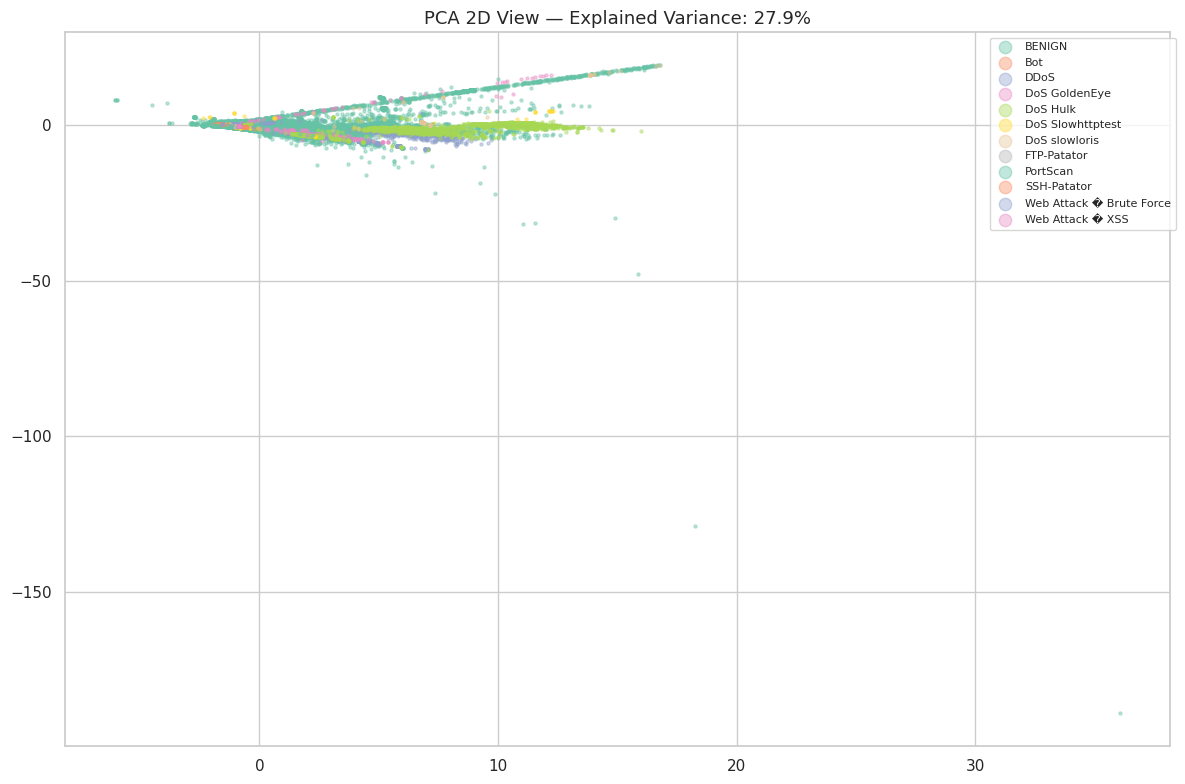

In [15]:
X_scaled = StandardScaler().fit_transform(X_eda.fillna(0))
pca = PCA(n_components=2, random_state=RANDOM_STATE)
components = pca.fit_transform(X_scaled)
pca_df = pd.DataFrame({'PC1': components[:, 0], 'PC2': components[:, 1], 'Label': y_eda.values})

plt.figure(figsize=(12, 8))
for label in sorted(pca_df['Label'].unique()):
    subset = pca_df[pca_df['Label'] == label]
    plt.scatter(subset['PC1'], subset['PC2'], label=le.classes_[label], alpha=0.4, s=5)
plt.title(f'PCA 2D View — Explained Variance: {pca.explained_variance_ratio_.sum()*100:.1f}%', fontsize=13)
plt.legend(markerscale=4, bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout()
plt.savefig('final_model/plots/c1_06_pca_2d.png', dpi=150)
plt.show()

**After preprocessing:** 2,830,743 raw rows -> 2,522,294 rows, 48 features, 12 classes, split into
1,513,376 / 504,459 / 504,459 (train / val / test).

---
## 2. Baseline models

Five comparison models, all trained once on the full training split and scored on the same held-out test set
with one shared evaluation function, so the numbers are directly comparable:

| Model | How it deals with imbalance |
|---|---|
| LightGBM | built-in `is_unbalance` flag |
| XGBoost V1 | sklearn "balanced" sample weights |
| XGBoost V2 | SMOTE oversampling of every non-majority class |
| XGBoost V3 | balanced weights x hand-picked boosts (XSS x5, Bot x3, Brute Force x2) |
| XGBoost V4 | balanced weights x revised hand-picked boosts (XSS x8, Bot x1.5), 700 trees |

V3 and V4 are the "manual tuning" approach that ACS-XGBoost is meant to replace.

In [16]:
# reload the splits if this section is run in a fresh session
if "X_train" not in globals():
    X_train = pd.read_parquet("final_model/X_train.parquet")
    X_val = pd.read_parquet("final_model/X_val.parquet")
    X_test = pd.read_parquet("final_model/X_test.parquet")
    y_train = pd.read_parquet("final_model/y_train.parquet")["y"]
    y_val = pd.read_parquet("final_model/y_val.parquet")["y"]
    y_test = pd.read_parquet("final_model/y_test.parquet")["y"]
    le = joblib.load("final_model/label_encoder.pkl")

classes_present = sorted(y_test.unique().tolist())
print(f"Classes present in test set: {len(classes_present)}")

Classes present in test set: 12


In [17]:
def get_class_index(label_encoder, keyword):
    """Look up a class index by (part of) its name instead of hard-coding the integer."""
    matches = [i for i, name in enumerate(label_encoder.classes_) if keyword.lower() in name.lower()]
    if len(matches) != 1:
        raise ValueError(f"Expected one class matching '{keyword}', found "
                         f"{[label_encoder.classes_[i] for i in matches]}")
    return matches[0]


def detect_gpu():
    try:
        r = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,memory.free",
                            "--format=csv,noheader"], capture_output=True, text=True, timeout=10)
        if r.returncode == 0 and r.stdout.strip():
            return r.stdout.strip()
    except Exception:
        pass
    return None


gpu_info = detect_gpu()
GPU_AVAILABLE = gpu_info is not None
XGB_DEVICE = "cuda" if GPU_AVAILABLE else "cpu"

print("  System Specifications")
print(f"  OS              : {platform.system()} {platform.release()}")
print(f"  Python          : {platform.python_version()}")
print(f"  CPU cores       : {psutil.cpu_count(logical=True)}")
print(f"  Total RAM       : {psutil.virtual_memory().total / 1e9:.1f} GB")
print(f"  Available RAM   : {psutil.virtual_memory().available / 1e9:.1f} GB")
print(f"  GPU             : {gpu_info or 'Not detected, falling back to CPU'}")
print(f"\n  XGBoost version : {xgb.__version__}")
print(f"  LightGBM version: {lgb.__version__}")
print(f"\n  XGBoost will use device = '{XGB_DEVICE}'")

  System Specifications
  OS              : Linux 6.12.90+
  Python          : 3.12.13
  CPU cores       : 4
  Total RAM       : 33.7 GB
  Available RAM   : 20.2 GB
  GPU             : Tesla P100-PCIE-16GB, 16384 MiB, 16270 MiB

  XGBoost version : 3.2.0
  LightGBM version: 4.6.0

  XGBoost will use device = 'cuda'


### Shared evaluation function

Every model, baselines and ACS-XGBoost alike, goes through this one function. It records accuracy, balanced
accuracy, macro precision/recall/F1, MCC, Cohen's kappa, micro and macro ROC-AUC, timings and memory use, and
it saves a normalised confusion matrix plus ROC and precision-recall curves.

**Primary metric: macro F1.** Accuracy is dominated by the BENIGN class and barely moves between models.

In [18]:
def get_memory_usage():
    ram_mb = psutil.Process(os.getpid()).memory_info().rss / 1e6
    vram_mb = 0
    if GPU_AVAILABLE:
        try:
            r = subprocess.run(["nvidia-smi", "--query-gpu=memory.used", "--format=csv,noheader,nounits"],
                               capture_output=True, text=True, timeout=10)
            vram_mb = float(r.stdout.strip().split("\n")[0])
        except Exception:
            vram_mb = 0
    return ram_mb, vram_mb


def full_evaluation(model, model_name, X_val_set, y_val_set, X_te, y_te,
                    train_time, le, classes_present, cmap="Blues"):
    """Score one model on the test set, save its plots, return (results dict, y_pred, y_score)."""
    t0 = time.time()
    model.predict(X_val_set)
    val_time = time.time() - t0

    t0 = time.time()
    y_pred = model.predict(X_te)
    inf_time = time.time() - t0
    y_score = model.predict_proba(X_te)
    ram_mb, vram_mb = get_memory_usage()

    labels = classes_present
    names = [le.classes_[i] for i in labels]

    acc = (y_te == y_pred).mean() * 100
    bal_acc = balanced_accuracy_score(y_te, y_pred) * 100
    mcc = matthews_corrcoef(y_te, y_pred)
    kappa = cohen_kappa_score(y_te, y_pred)
    f1_mac = f1_score(y_te, y_pred, average="macro", labels=labels, zero_division=0) * 100
    f1_wt = f1_score(y_te, y_pred, average="weighted", labels=labels, zero_division=0) * 100
    prec_mac = precision_score(y_te, y_pred, average="macro", labels=labels, zero_division=0) * 100
    rec_mac = recall_score(y_te, y_pred, average="macro", labels=labels, zero_division=0) * 100
    prec_micro = precision_score(y_te, y_pred, average="micro", labels=labels, zero_division=0) * 100
    rec_micro = recall_score(y_te, y_pred, average="micro", labels=labels, zero_division=0) * 100

    print(f"\n  {model_name} — Test Set Results")
    print(f"  Accuracy           : {acc:.4f}%")
    print(f"  Precision (micro)  : {prec_micro:.4f}%")
    print(f"  Recall (micro)     : {rec_micro:.4f}%")
    print(f"  Balanced Accuracy  : {bal_acc:.4f}%")
    print(f"  Macro Precision    : {prec_mac:.4f}%")
    print(f"  Macro Recall       : {rec_mac:.4f}%")
    print(f"  Macro F1           : {f1_mac:.4f}%   <- PRIMARY METRIC")
    print(f"  Weighted F1        : {f1_wt:.4f}%")
    print(f"  MCC                : {mcc:.4f}")
    print(f"  Cohen Kappa        : {kappa:.4f}")
    print(f"  Train Time         : {train_time:.2f} sec")
    print(f"  Validation Time    : {val_time:.4f} sec")
    print(f"  Inference Time     : {inf_time:.4f} sec")
    print(f"  RAM Usage          : {ram_mb:.0f} MB")
    print(f"  VRAM Usage         : {vram_mb:.0f} MB")

    print(f"\n=== {model_name} — Per-Class Classification Report ===")
    print(classification_report(y_te, y_pred, labels=labels, target_names=names, digits=4, zero_division=0))

    report = classification_report(y_te, y_pred, labels=labels, target_names=names,
                                   digits=4, zero_division=0, output_dict=True)
    per_class = pd.DataFrame({
        "Class": names,
        "Precision %": [round(report[n]["precision"] * 100, 2) for n in names],
        "Recall %": [round(report[n]["recall"] * 100, 2) for n in names],
        "F1 %": [round(report[n]["f1-score"] * 100, 2) for n in names],
        "Support": [report[n]["support"] for n in names],
    })
    safe_name = model_name.replace(" ", "_").replace("/", "_")
    per_class.to_csv(f"final_model/tables/perclass_{safe_name}.csv", index=False)

    # confusion matrix (row-normalised)
    cm = confusion_matrix(y_te, y_pred, labels=labels)
    cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis] * 100
    plt.figure(figsize=(13, 10))
    sns.heatmap(cm_norm, annot=True, fmt=".1f", cmap=cmap, xticklabels=names, yticklabels=names,
                linewidths=0.5, cbar_kws={"label": "Recall %"})
    plt.title(f"{model_name} — Confusion Matrix (Normalized %)", fontsize=13)
    plt.ylabel("Actual")
    plt.xlabel("Predicted")
    plt.xticks(rotation=45, ha="right", fontsize=8)
    plt.yticks(rotation=0, fontsize=8)
    plt.tight_layout()
    plt.savefig(f"final_model/plots/{safe_name}_confusion_matrix.png", dpi=150)
    plt.show()

    # one-vs-rest ROC. y_te_bin columns follow `labels`; y_score columns follow the encoded class id.
    y_te_bin = label_binarize(y_te, classes=labels)
    fpr, tpr, roc_auc = {}, {}, {}
    for pos, cls in enumerate(labels):
        if cls < y_score.shape[1]:
            fpr[cls], tpr[cls], _ = roc_curve(y_te_bin[:, pos], y_score[:, cls])
            roc_auc[cls] = auc(fpr[cls], tpr[cls])
    fpr_micro, tpr_micro, _ = roc_curve(y_te_bin.ravel(), y_score[:, labels].ravel())
    roc_micro = auc(fpr_micro, tpr_micro)
    roc_macro = float(np.mean(list(roc_auc.values()))) if roc_auc else float("nan")

    weakest = sorted(roc_auc, key=roc_auc.get)[:6]
    colors = plt.cm.Set2(np.linspace(0, 1, max(len(weakest), 1)))
    plt.figure(figsize=(11, 7))
    for cls, color in zip(weakest, colors):
        plt.plot(fpr[cls], tpr[cls], lw=1.5, color=color, label=f"{le.classes_[cls]} (AUC={roc_auc[cls]:.3f})")
    plt.plot(fpr_micro, tpr_micro, "k--", lw=2.5, label=f"Micro Avg (AUC={roc_micro:.4f})")
    plt.plot([0, 1], [0, 1], "k:", lw=1)
    plt.xlim([0, 1])
    plt.ylim([0, 1.05])
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{model_name} — ROC-AUC (One-vs-Rest, weakest 6 classes shown)", fontsize=12)
    plt.legend(loc="lower right", fontsize=8)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"final_model/plots/{safe_name}_roc_auc.png", dpi=150)
    plt.show()
    print(f"  Micro ROC-AUC : {roc_micro:.4f}   Macro ROC-AUC : {roc_macro:.4f}")

    # precision-recall for the first 6 classes
    plt.figure(figsize=(11, 7))
    colors = plt.cm.Set2(np.linspace(0, 1, min(6, len(labels))))
    for pos, (cls, color) in enumerate(zip(labels[:6], colors)):
        if cls < y_score.shape[1]:
            prec, rec, _ = precision_recall_curve(y_te_bin[:, pos], y_score[:, cls])
            ap = average_precision_score(y_te_bin[:, pos], y_score[:, cls])
            plt.plot(rec, prec, lw=1.5, color=color, label=f"{le.classes_[cls]} (AP={ap:.3f})")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"{model_name} — Precision-Recall Curve", fontsize=12)
    plt.legend(loc="lower left", fontsize=8)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"final_model/plots/{safe_name}_pr_curve.png", dpi=150)
    plt.show()

    results = {
        "Model": model_name, "Accuracy": round(acc, 4), "Precision (micro)": round(prec_micro, 4),
        "Recall (micro)": round(rec_micro, 4), "Balanced Accuracy": round(bal_acc, 4),
        "Macro Precision": round(prec_mac, 4), "Macro Recall": round(rec_mac, 4),
        "Macro F1": round(f1_mac, 4), "Weighted F1": round(f1_wt, 4), "MCC": round(mcc, 4),
        "Cohen Kappa": round(kappa, 4), "Micro ROC-AUC": round(roc_micro, 4),
        "Macro ROC-AUC": round(roc_macro, 4), "Train Time (s)": round(train_time, 2),
        "Val Time (s)": round(val_time, 4), "Infer Time (s)": round(inf_time, 4),
        "RAM (MB)": round(ram_mb, 0), "VRAM (MB)": round(vram_mb, 0),
    }
    return results, y_pred, y_score


all_results = []
all_predictions = {}     # model name -> (y_pred, y_score)

### Model 1: LightGBM

  Training Model 1/5: LightGBM
Trained in 1.9 min

  LightGBM — Test Set Results
  Accuracy           : 99.7157%
  Precision (micro)  : 99.7157%
  Recall (micro)     : 99.7157%
  Balanced Accuracy  : 89.3132%
  Macro Precision    : 83.7106%
  Macro Recall       : 89.3132%
  Macro F1           : 86.1290%   <- PRIMARY METRIC
  Weighted F1        : 99.7310%
  MCC                : 0.9906
  Cohen Kappa        : 0.9906
  Train Time         : 115.52 sec
  Validation Time    : 3.7183 sec
  Inference Time     : 3.9792 sec
  RAM Usage          : 12371 MB
  VRAM Usage         : 0 MB

=== LightGBM — Per-Class Classification Report ===
                          precision    recall  f1-score   support

                  BENIGN     0.9994    0.9977    0.9986    419297
                     Bot     0.5957    0.7724    0.6726       391
                    DDoS     1.0000    0.9993    0.9996     25603
           DoS GoldenEye     0.9570    0.9854    0.9710      2057
                DoS Hulk     0.9980   

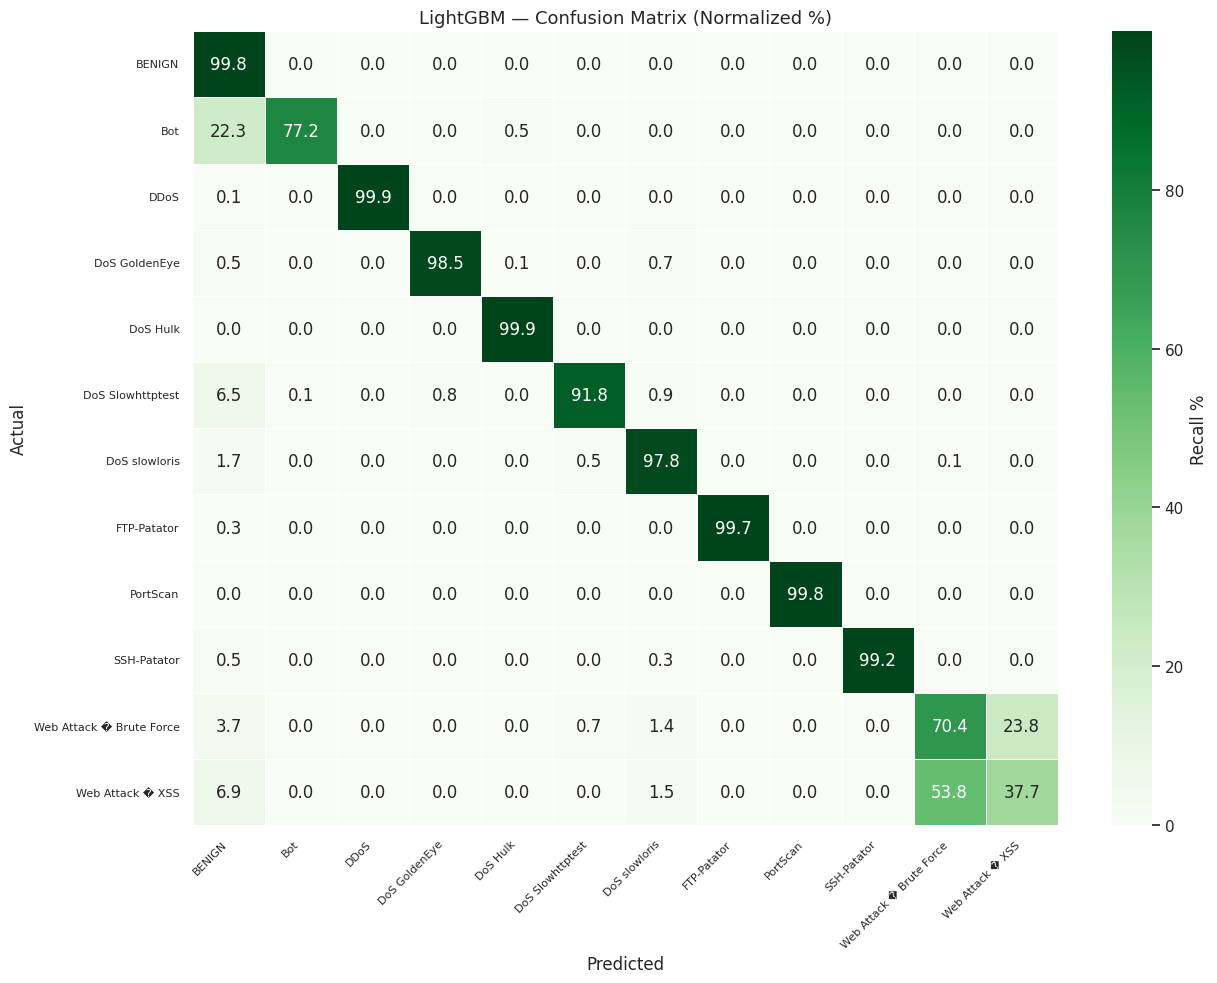

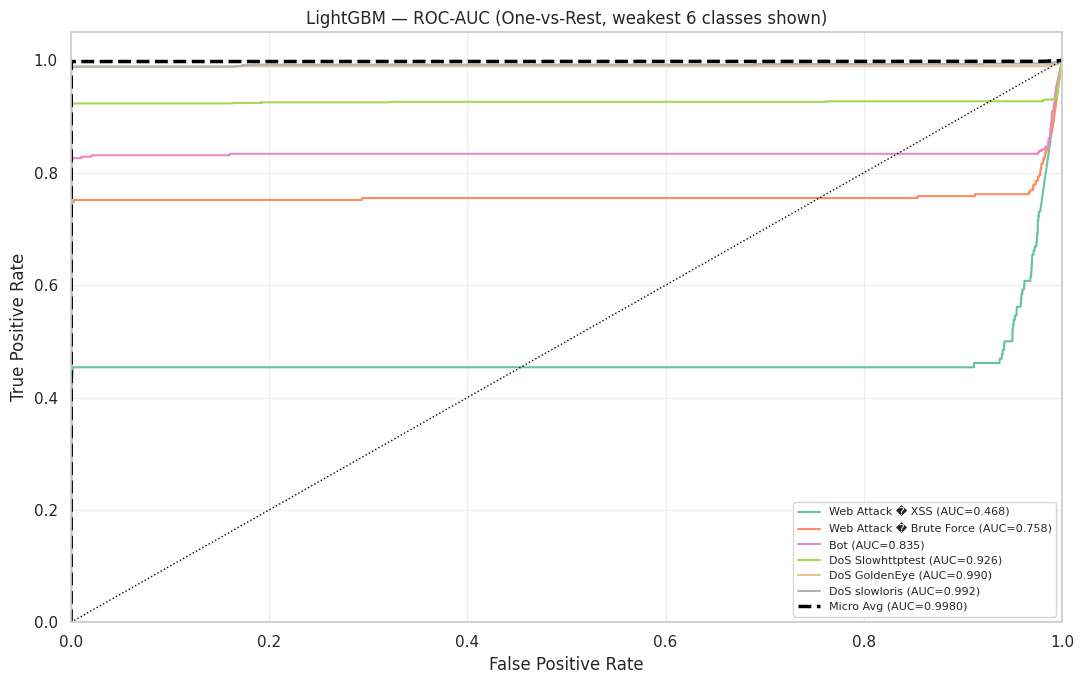

  Micro ROC-AUC : 0.9980   Macro ROC-AUC : 0.9134


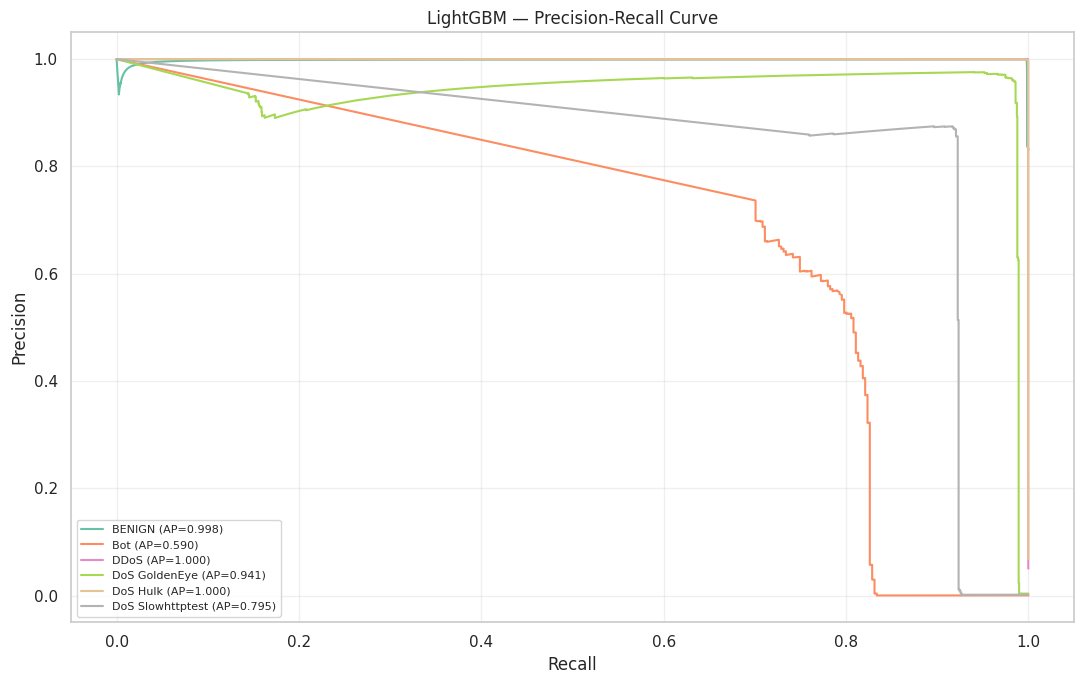

In [19]:
print("Training Model 1/5: LightGBM")
t0 = time.time()
lgb_model = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=63, max_depth=-1,
                               is_unbalance=True, n_jobs=-1, random_state=RANDOM_STATE, verbose=-1)
lgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)],
              callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(100)])
lgb_time = time.time() - t0
print(f"Trained in {lgb_time / 60:.1f} min")

res, y_pred, y_score = full_evaluation(lgb_model, "LightGBM", X_val, y_val, X_test, y_test,
                                       lgb_time, le, classes_present, cmap="Greens")
all_results.append(res)
all_predictions["LightGBM"] = (y_pred, y_score)
joblib.dump(lgb_model, "final_model/lgb_model.pkl")

### Models 2 to 5: XGBoost variants

All four share the same base configuration (500 trees, depth 6, learning rate 0.05, early stopping on the
validation set), so the only thing that changes between them is *how the imbalance is handled*.

In [20]:
def make_xgb(n_estimators=500):
    return xgb.XGBClassifier(
        n_estimators=n_estimators, learning_rate=0.05, max_depth=6,
        objective="multi:softprob", num_class=len(le.classes_), eval_metric="mlogloss",
        early_stopping_rounds=50, device=XGB_DEVICE, n_jobs=-1,
        random_state=RANDOM_STATE, verbosity=0)


def run_xgb(tag, key, X, y, weights=None, cmap="Blues", n_estimators=500):
    """Fit one XGBoost variant, evaluate it, and store its results."""
    model = make_xgb(n_estimators)
    t0 = time.time()
    model.fit(X, y, sample_weight=weights, eval_set=[(X_val, y_val)], verbose=100)
    elapsed = time.time() - t0
    print(f"Trained in {elapsed / 60:.1f} min")

    res, y_pred, y_score = full_evaluation(model, tag, X_val, y_val, X_test, y_test,
                                           elapsed, le, classes_present, cmap=cmap)
    all_results.append(res)
    all_predictions[key] = (y_pred, y_score)
    return model

  Training Model 2/5: XGBoost V1 (Balanced Weights)
[0]	validation_0-mlogloss:2.22660
[100]	validation_0-mlogloss:0.03676
[200]	validation_0-mlogloss:0.01057
[300]	validation_0-mlogloss:0.00788
[400]	validation_0-mlogloss:0.00713
[499]	validation_0-mlogloss:0.00680
Trained in 1.0 min

  XGBoost_V1 — Test Set Results
  Accuracy           : 99.8616%
  Precision (micro)  : 99.8616%
  Recall (micro)     : 99.8616%
  Balanced Accuracy  : 93.0202%
  Macro Precision    : 89.6796%
  Macro Recall       : 93.0202%
  Macro F1           : 91.0692%   <- PRIMARY METRIC
  Weighted F1        : 99.8664%
  MCC                : 0.9954
  Cohen Kappa        : 0.9954
  Train Time         : 60.30 sec
  Validation Time    : 2.1332 sec
  Inference Time     : 1.9838 sec
  RAM Usage          : 12583 MB
  VRAM Usage         : 409 MB

=== XGBoost_V1 — Per-Class Classification Report ===
                          precision    recall  f1-score   support

                  BENIGN     1.0000    0.9988    0.9994    419

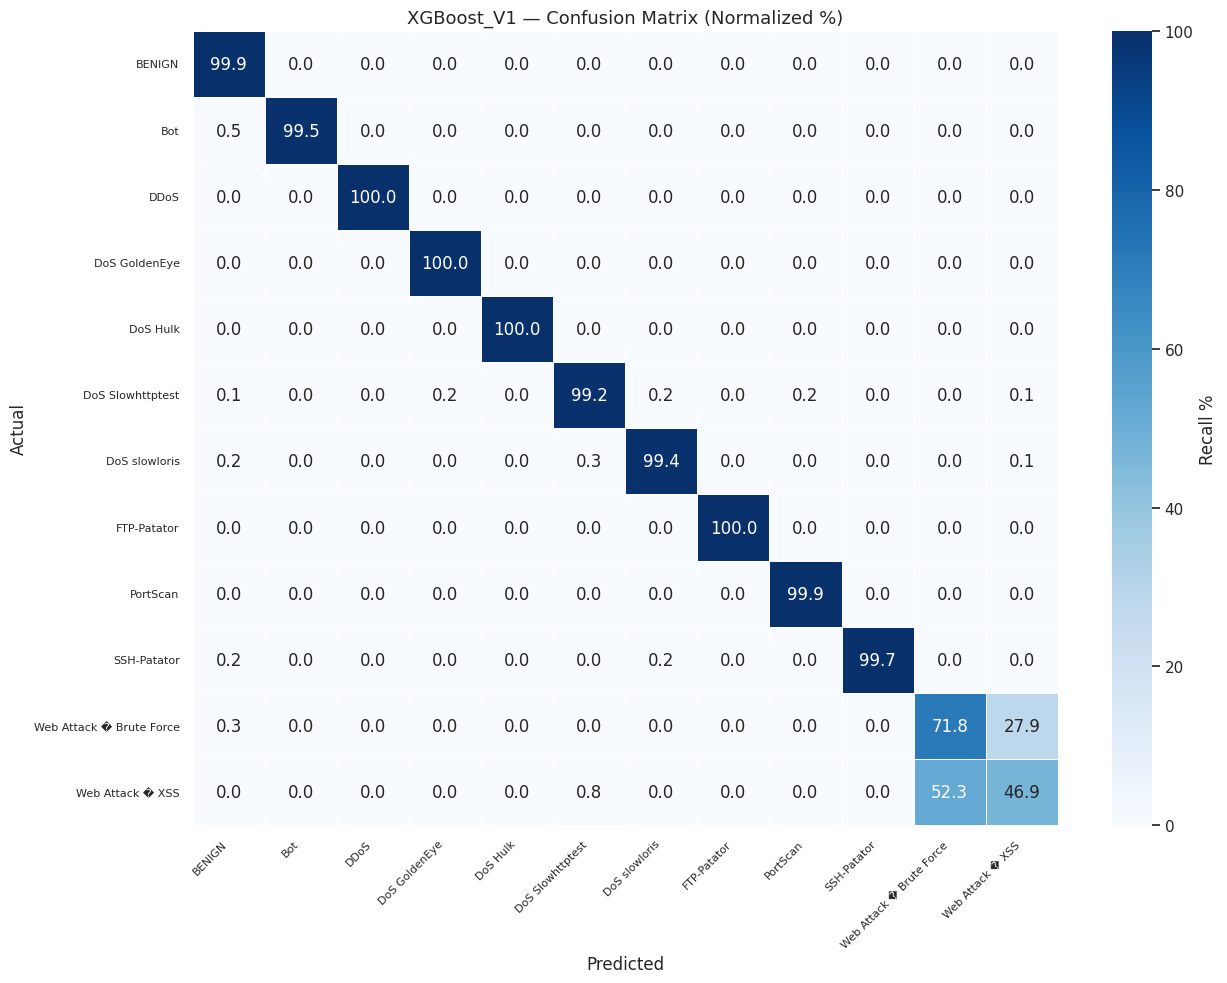

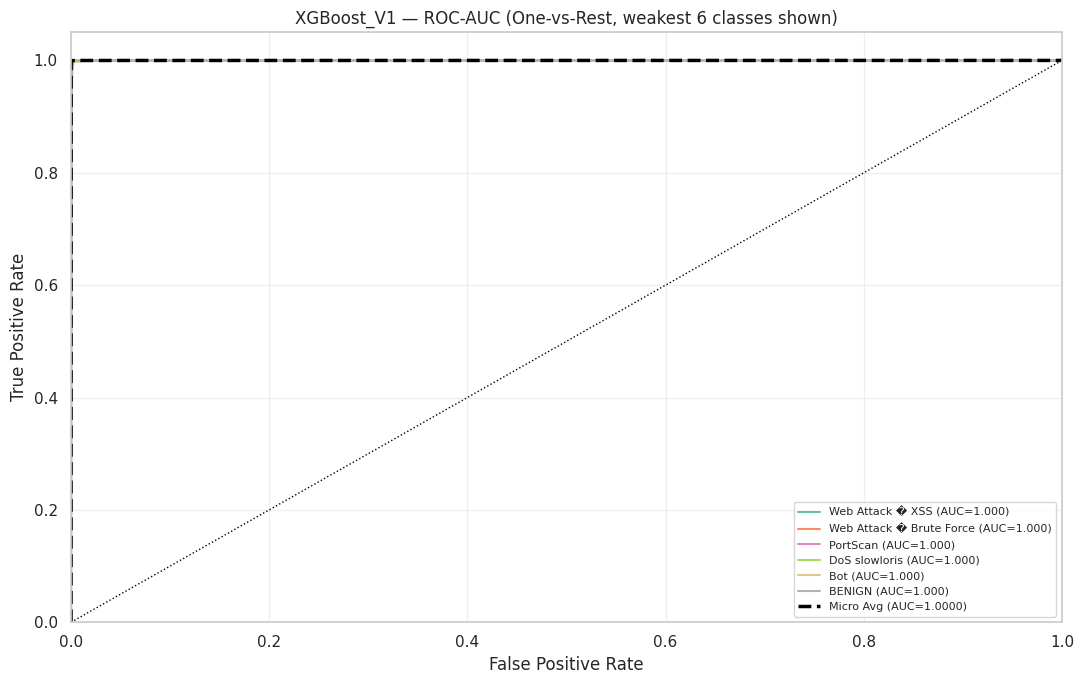

  Micro ROC-AUC : 1.0000   Macro ROC-AUC : 0.9999


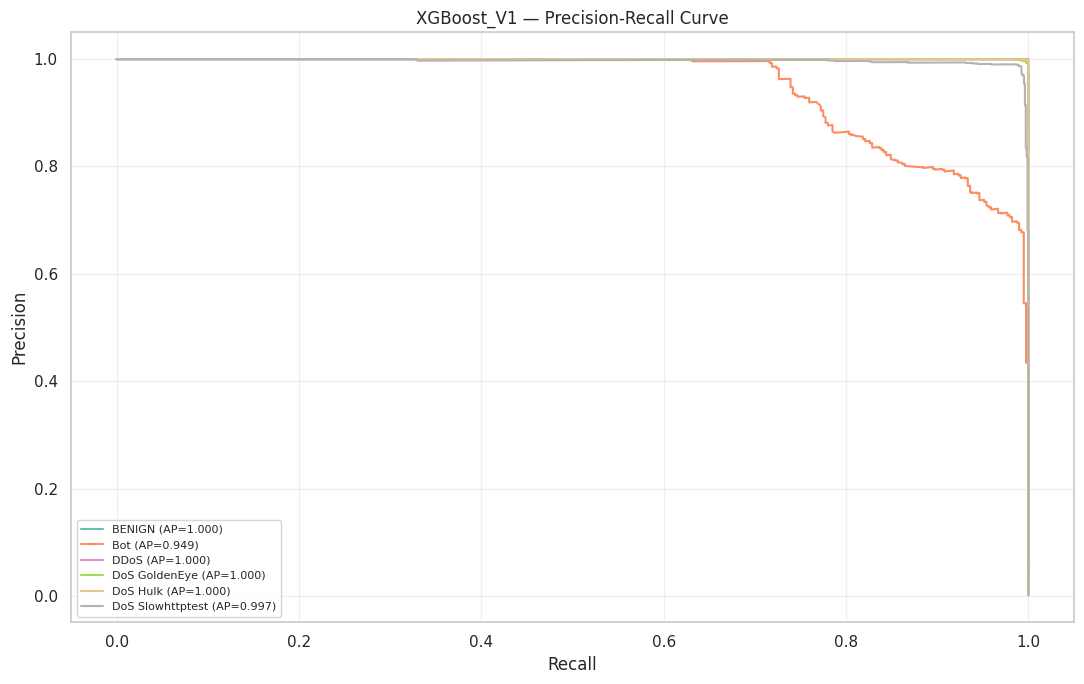

In [21]:
print("Training Model 2/5: XGBoost V1 (Balanced Weights)")
sw_v1 = compute_sample_weight(class_weight="balanced", y=y_train)
xgb_v1 = run_xgb("XGBoost_V1", "XGBoost V1", X_train, y_train, weights=sw_v1)
joblib.dump(xgb_v1, "final_model/xgb_v1.pkl")

  Training Model 3/5: XGBoost V2 (SMOTE)
Applying SMOTE to training data (rare classes only)...
Before SMOTE: 1,513,376 rows -> After SMOTE: 15,094,680 rows
[0]	validation_0-mlogloss:2.22706
[100]	validation_0-mlogloss:0.04292
[200]	validation_0-mlogloss:0.01346
[300]	validation_0-mlogloss:0.00975
[400]	validation_0-mlogloss:0.00834
[499]	validation_0-mlogloss:0.00775
Trained in 7.9 min

  XGBoost_V2_SMOTE — Test Set Results
  Accuracy           : 99.8186%
  Precision (micro)  : 99.8186%
  Recall (micro)     : 99.8186%
  Balanced Accuracy  : 93.8285%
  Macro Precision    : 88.6604%
  Macro Recall       : 93.8285%
  Macro F1           : 90.5021%   <- PRIMARY METRIC
  Weighted F1        : 99.8333%
  MCC                : 0.9940
  Cohen Kappa        : 0.9940
  Train Time         : 476.92 sec
  Validation Time    : 2.2995 sec
  Inference Time     : 2.1715 sec
  RAM Usage          : 18634 MB
  VRAM Usage         : 923 MB

=== XGBoost_V2_SMOTE — Per-Class Classification Report ===
           

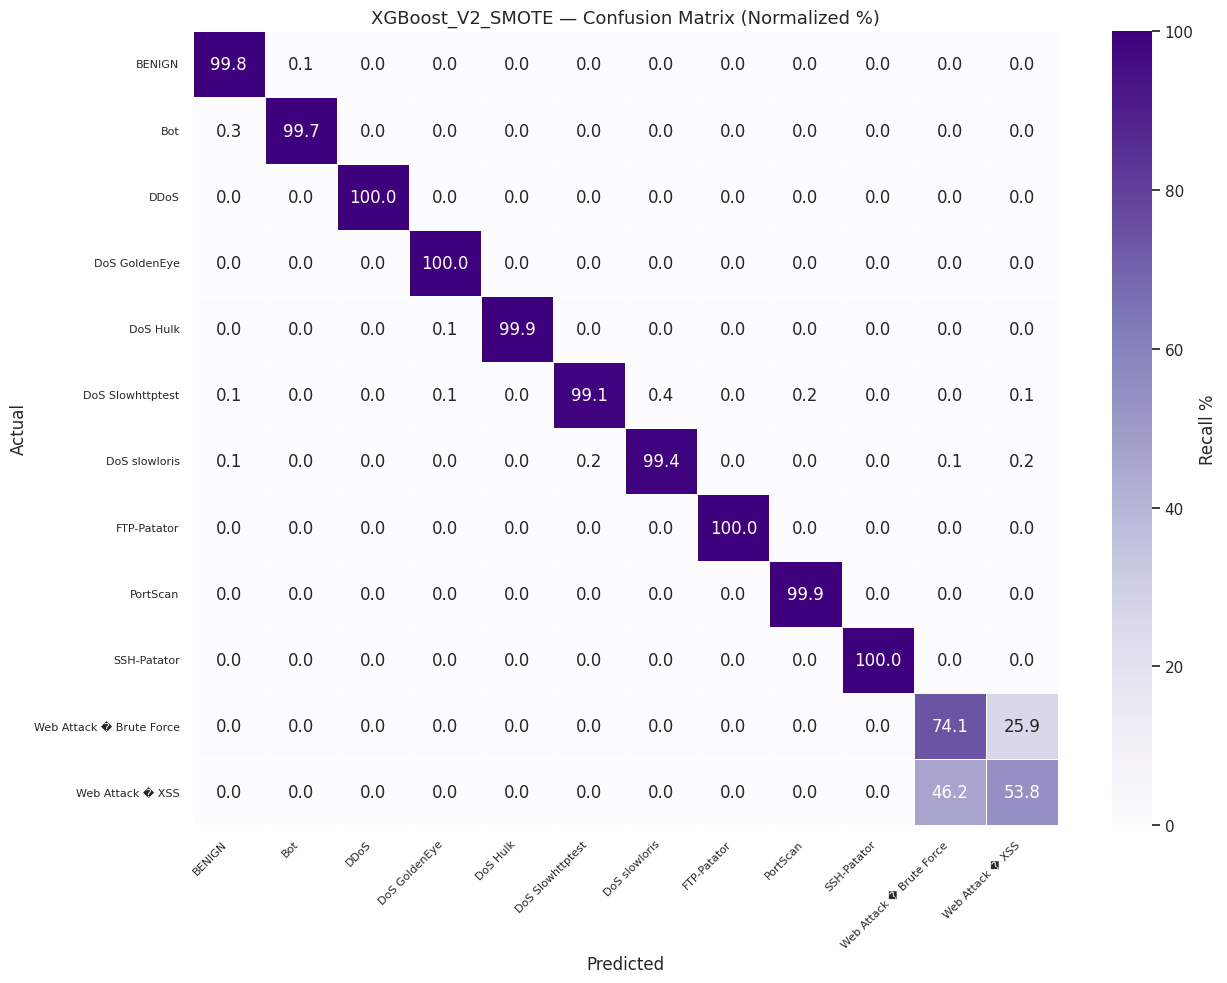

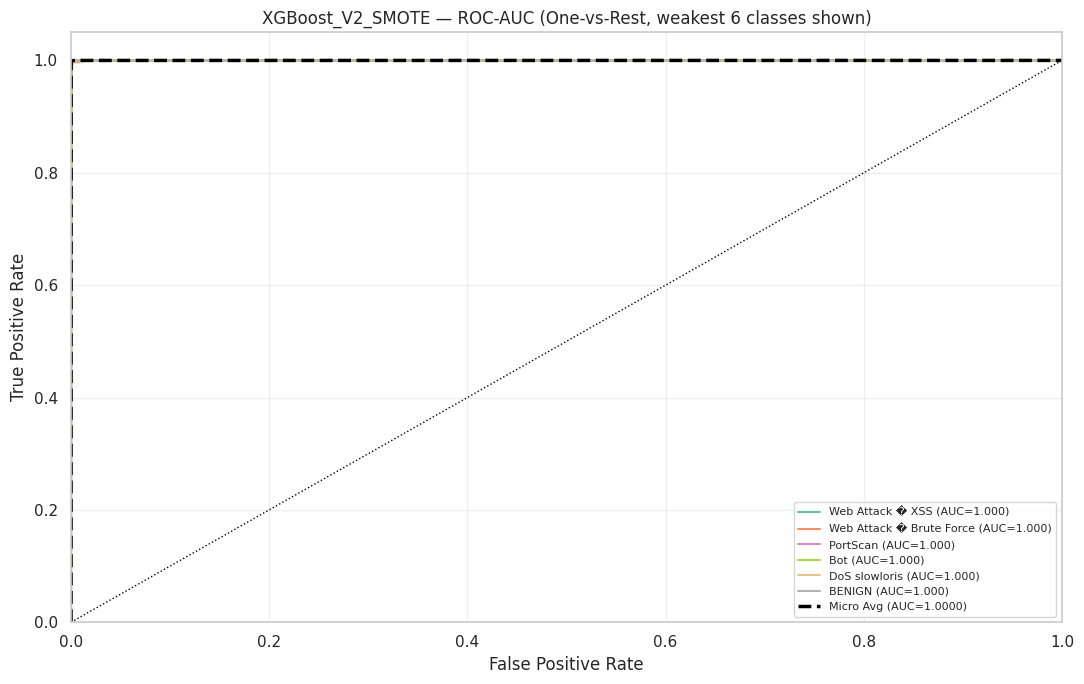

  Micro ROC-AUC : 1.0000   Macro ROC-AUC : 1.0000


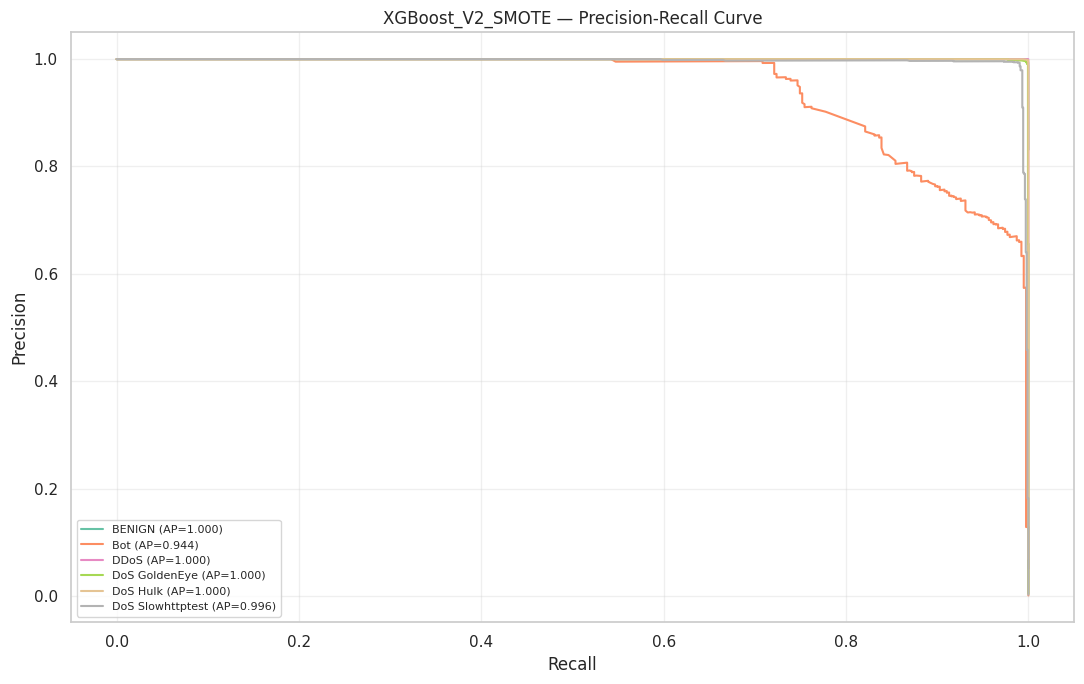

In [22]:
print("Training Model 3/5: XGBoost V2 (SMOTE)")
print("Applying SMOTE to training data (rare classes only)...")
# 'not majority' resamples every class except the largest. ('minority' would only touch the single rarest class.)
smote = SMOTE(sampling_strategy="not majority", k_neighbors=5, random_state=RANDOM_STATE)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)
print(f"Before SMOTE: {len(X_train):,} rows -> After SMOTE: {len(X_train_sm):,} rows")

xgb_v2 = run_xgb("XGBoost_V2_SMOTE", "XGBoost V2 SMOTE", X_train_sm, y_train_sm, cmap="Purples")
joblib.dump(xgb_v2, "final_model/xgb_v2_smote.pkl")

del X_train_sm, y_train_sm      # about 15M rows, free the memory
gc.collect()

  Training Model 4/5: XGBoost V3 (Manual Weights)
Manual weight boosts applied: {11: 5.0, 1: 3.0, 10: 2.0}
[0]	validation_0-mlogloss:2.60319
[100]	validation_0-mlogloss:0.04381
[200]	validation_0-mlogloss:0.01210
[300]	validation_0-mlogloss:0.00884
[400]	validation_0-mlogloss:0.00772
[499]	validation_0-mlogloss:0.00734
Trained in 1.0 min

  XGBoost_V3_Manual — Test Set Results
  Accuracy           : 99.8585%
  Precision (micro)  : 99.8585%
  Recall (micro)     : 99.8585%
  Balanced Accuracy  : 93.4167%
  Macro Precision    : 89.7355%
  Macro Recall       : 93.4167%
  Macro F1           : 91.2006%   <- PRIMARY METRIC
  Weighted F1        : 99.8642%
  MCC                : 0.9953
  Cohen Kappa        : 0.9953
  Train Time         : 60.06 sec
  Validation Time    : 2.1526 sec
  Inference Time     : 2.0167 sec
  RAM Usage          : 12872 MB
  VRAM Usage         : 987 MB

=== XGBoost_V3_Manual — Per-Class Classification Report ===
                          precision    recall  f1-score   su

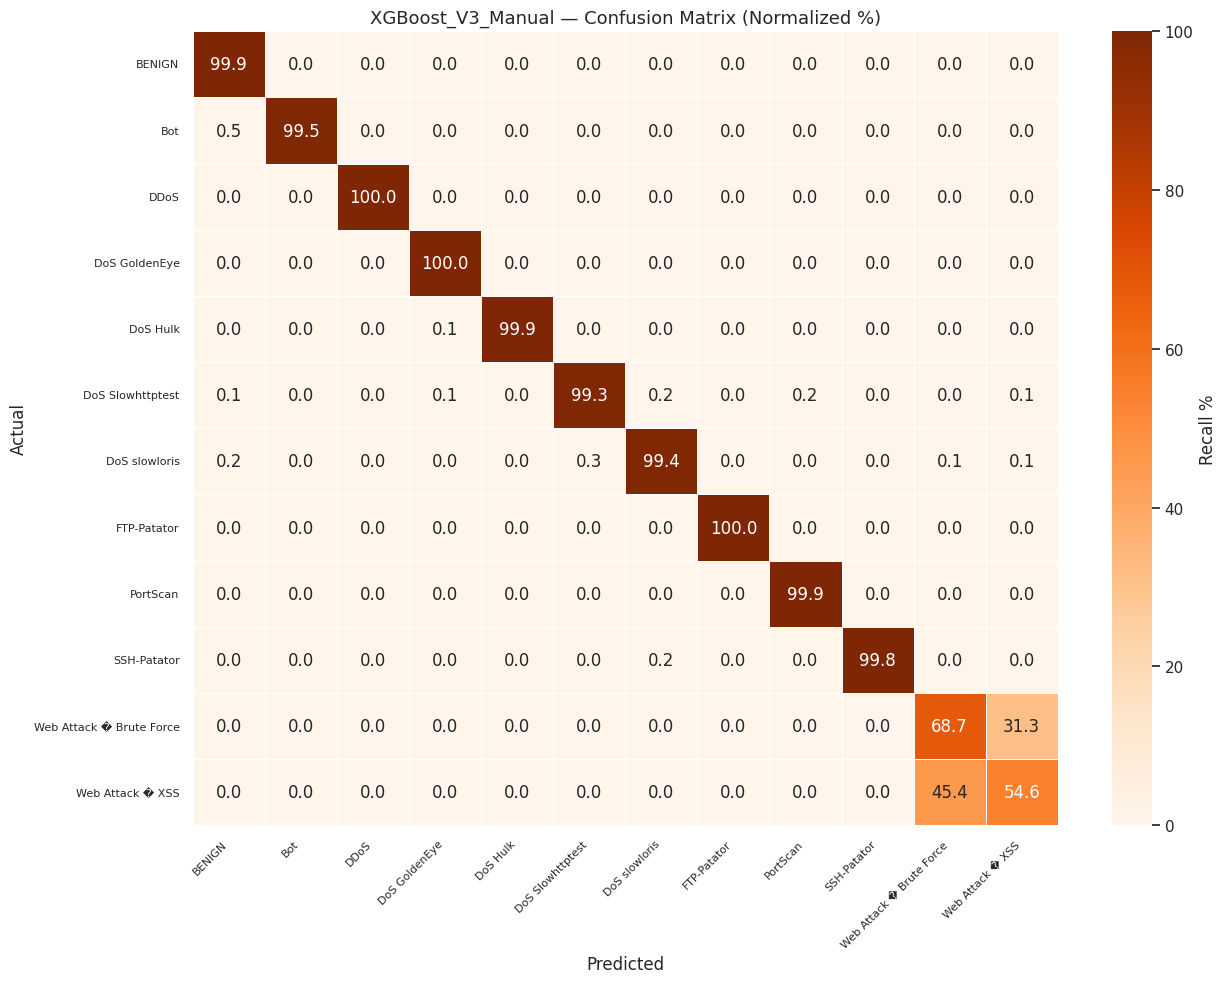

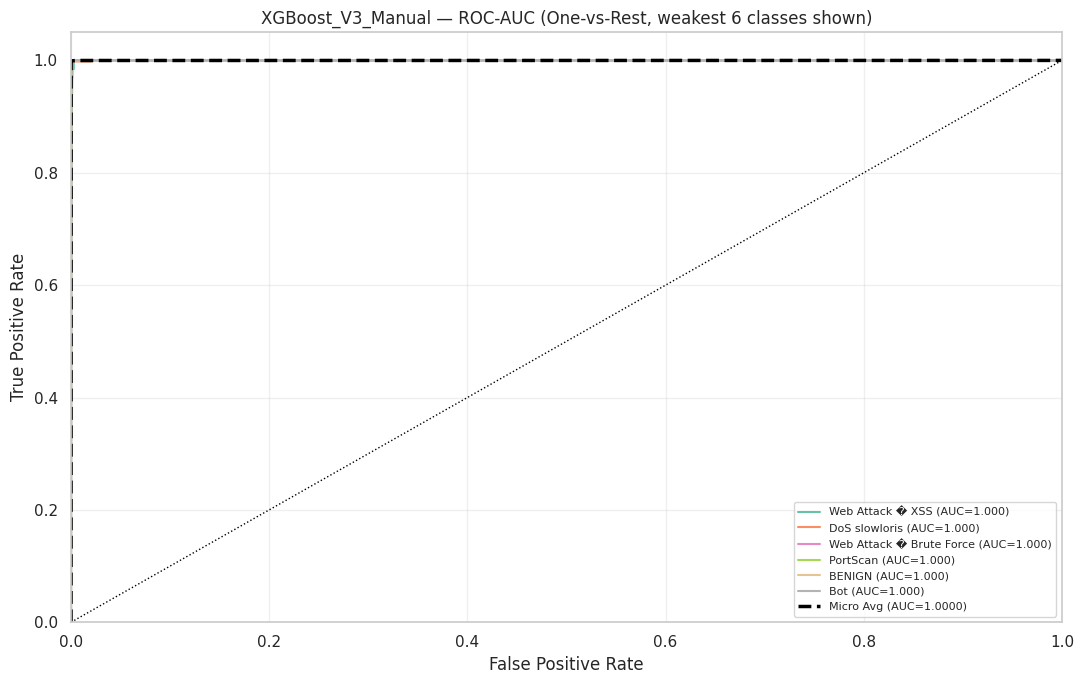

  Micro ROC-AUC : 1.0000   Macro ROC-AUC : 0.9999


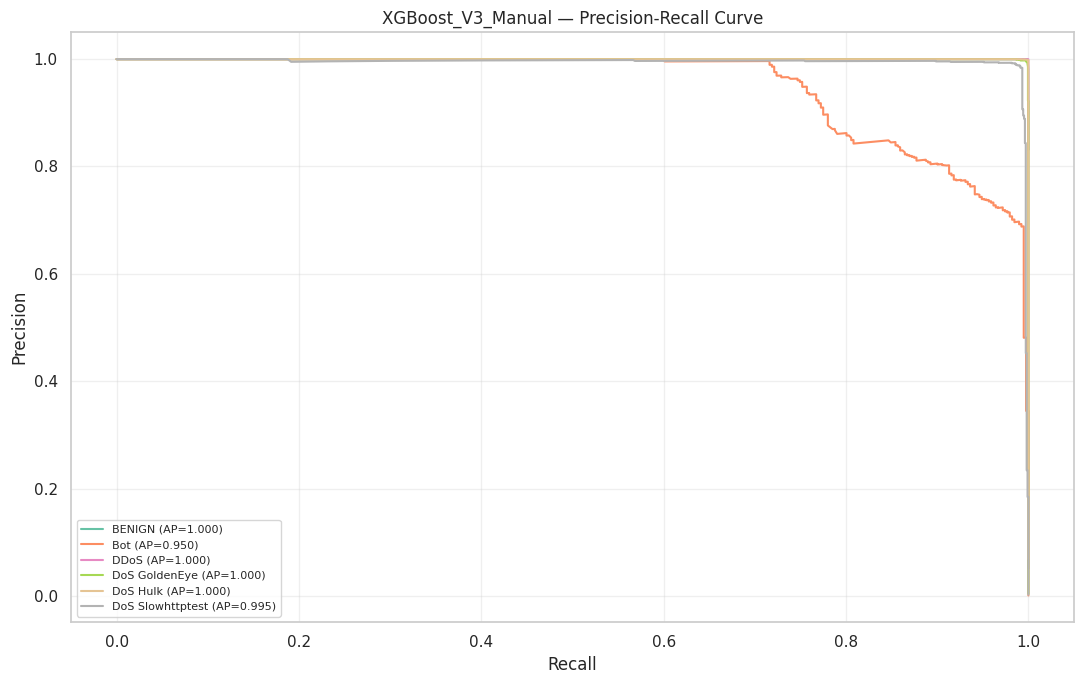

In [23]:
print("Training Model 4/5: XGBoost V3 (Manual Weights)")
idx_xss = get_class_index(le, "XSS")
idx_bot = get_class_index(le, "Bot")
idx_bruteforce = get_class_index(le, "Brute Force")

sw_v3 = compute_sample_weight(class_weight="balanced", y=y_train)
boost_v3 = {idx_xss: 5.0, idx_bot: 3.0, idx_bruteforce: 2.0}
for cls_idx, boost in boost_v3.items():
    sw_v3[y_train.values == cls_idx] *= boost
print(f"Manual weight boosts applied: {boost_v3}")

xgb_v3 = run_xgb("XGBoost_V3_Manual", "XGBoost V3 Manual", X_train, y_train, weights=sw_v3, cmap="Oranges")
joblib.dump(xgb_v3, "final_model/xgb_v3_manual.pkl")

  Training Model 5/5: XGBoost V4 (Tuned Weights)
Tuned weight boosts applied: {11: 8.0, 1: 1.5}
[0]	validation_0-mlogloss:2.56319
[100]	validation_0-mlogloss:0.04147
[200]	validation_0-mlogloss:0.01185
[300]	validation_0-mlogloss:0.00860
[400]	validation_0-mlogloss:0.00761
[500]	validation_0-mlogloss:0.00720
[600]	validation_0-mlogloss:0.00698
[699]	validation_0-mlogloss:0.00685
Trained in 1.4 min

  XGBoost_V4_Tuned — Test Set Results
  Accuracy           : 99.8650%
  Precision (micro)  : 99.8650%
  Recall (micro)     : 99.8650%
  Balanced Accuracy  : 93.6440%
  Macro Precision    : 90.2822%
  Macro Recall       : 93.6440%
  Macro F1           : 91.6276%   <- PRIMARY METRIC
  Weighted F1        : 99.8698%
  MCC                : 0.9955
  Cohen Kappa        : 0.9955
  Train Time         : 82.71 sec
  Validation Time    : 2.8533 sec
  Inference Time     : 2.6623 sec
  RAM Usage          : 13042 MB
  VRAM Usage         : 1053 MB

=== XGBoost_V4_Tuned — Per-Class Classification Report ===


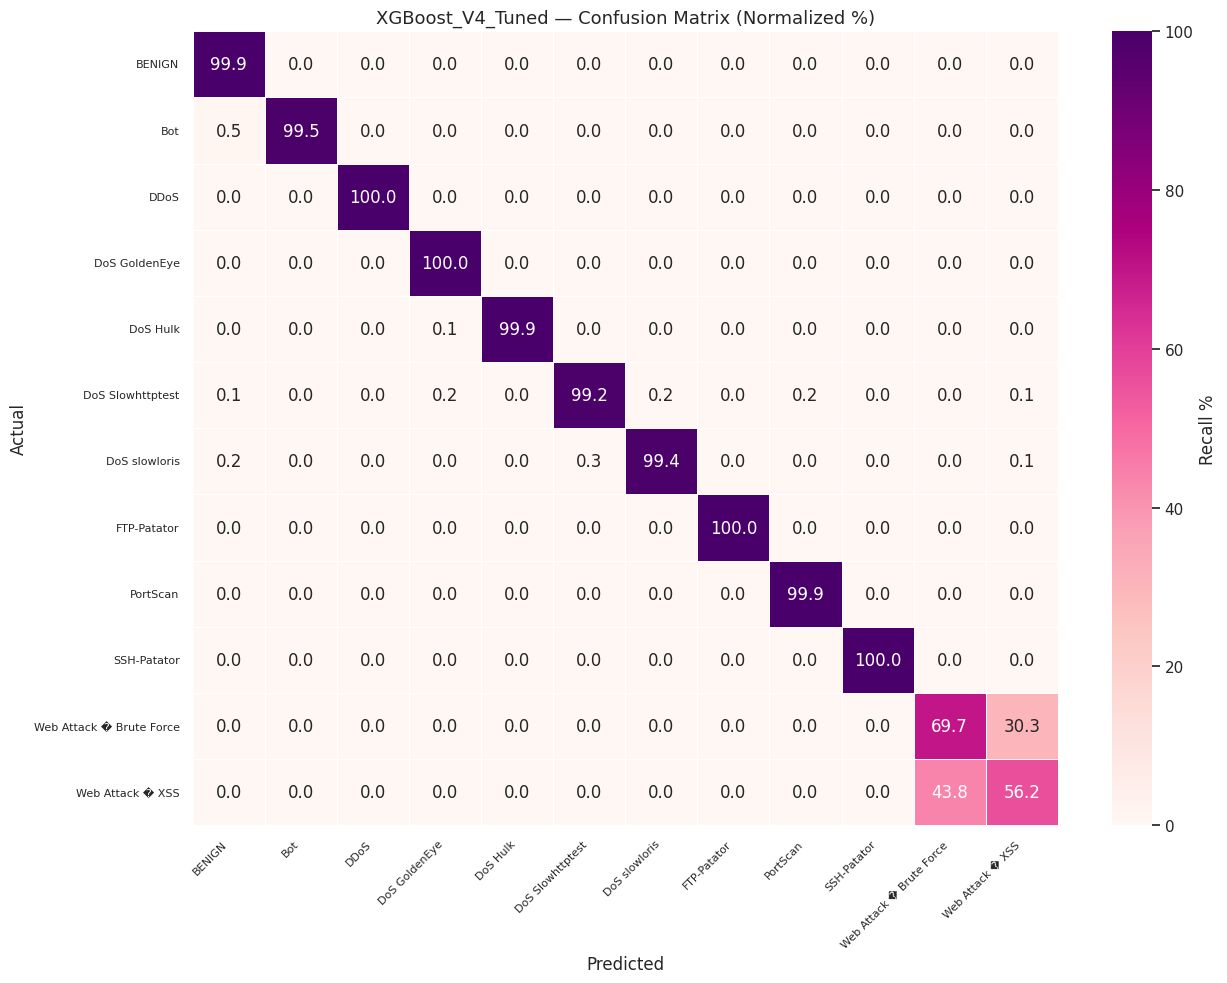

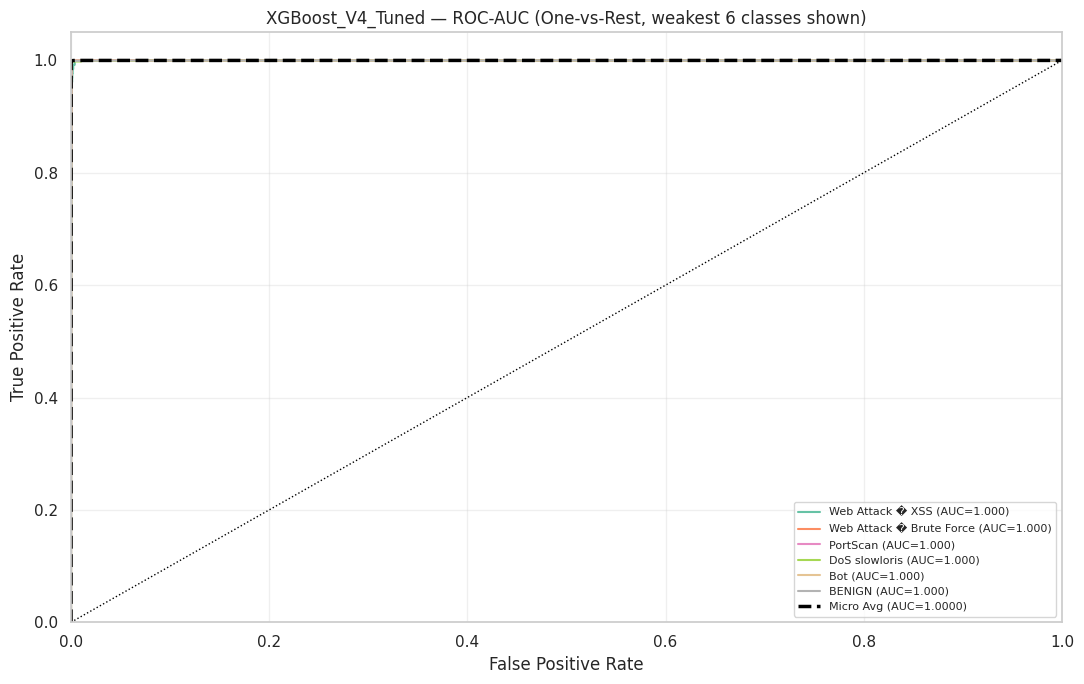

  Micro ROC-AUC : 1.0000   Macro ROC-AUC : 0.9999


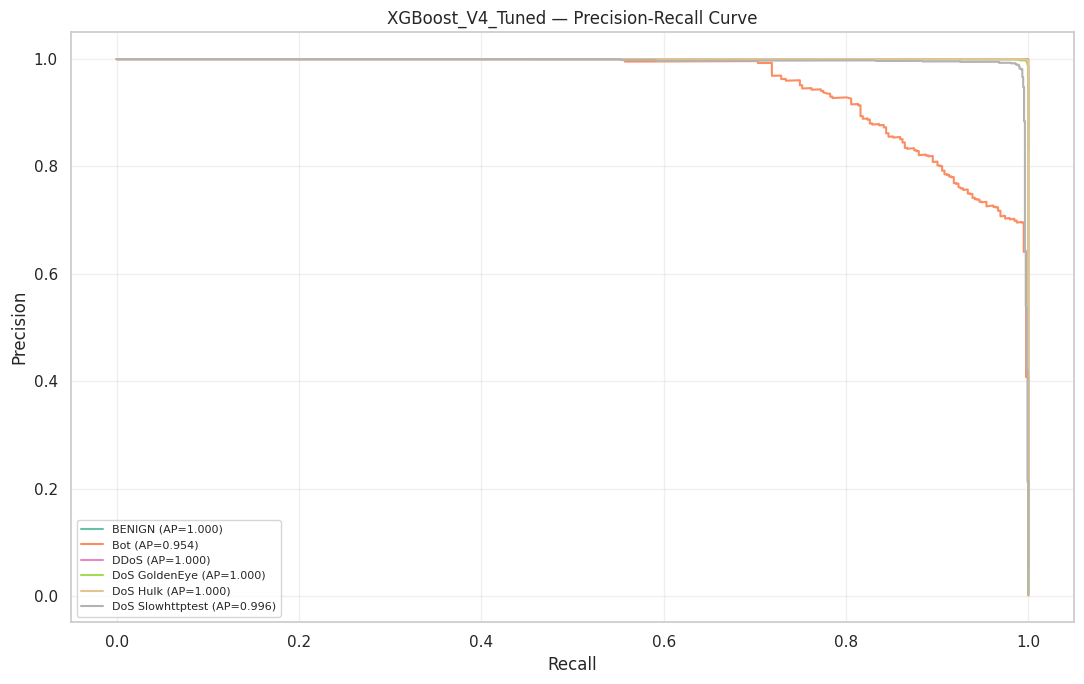

In [24]:
print("Training Model 5/5: XGBoost V4 (Tuned Weights)")
sw_v4 = compute_sample_weight(class_weight="balanced", y=y_train)
boost_v4 = {idx_xss: 8.0, idx_bot: 1.5}
for cls_idx, boost in boost_v4.items():
    sw_v4[y_train.values == cls_idx] *= boost
print(f"Tuned weight boosts applied: {boost_v4}")

xgb_v4 = run_xgb("XGBoost_V4_Tuned", "XGBoost V4 Tuned", X_train, y_train, weights=sw_v4,
                 cmap="RdPu", n_estimators=700)
joblib.dump(xgb_v4, "final_model/xgb_v4_tuned.pkl")

### Baseline comparison

In [25]:
baseline_df = pd.DataFrame(all_results).sort_values("Macro F1", ascending=False)
baseline_df.to_csv("final_model/baseline_results.csv", index=False)
joblib.dump(all_predictions, "final_model/baseline_predictions.pkl")

show_cols = ["Model", "Accuracy", "Balanced Accuracy", "Macro F1", "MCC", "Macro ROC-AUC", "Train Time (s)"]
baseline_df[show_cols]

,Model,Accuracy,Balanced Accuracy,Macro F1,MCC,Macro ROC-AUC,Train Time (s)
0,LightGBM,99.7157,89.3132,86.1290,0.9906,0.9134,115.5200


Accuracy is practically identical across the XGBoost variants (99.82 to 99.87%), which is exactly why it is not
informative here. The spread shows up in macro F1:

- **LightGBM** is clearly behind (86.1%), mostly on the rare classes.
- **SMOTE (V2)** takes about 8x longer to train because it grows the training set from 1.5M to 15M rows, and
  still ends up below plain balanced weights on macro F1.
- **Hand-tuned weights (V3, V4)** edge out V1, which is the benefit ACS-XGBoost tries to get without picking the
  numbers by hand.

---
## 3. ACS-XGBoost

### 3.1 The idea

Hand-picked boosts like "XSS x5" are guesses, and they need redoing whenever the data changes. ACS-XGBoost
builds a weight for every class from two things that can be measured:

- **Frequency weight:** rare classes get more weight

  $$W_f(c) = \frac{N}{K \cdot N_c}$$

- **Difficulty weight:** classes a first-pass model struggles with get more weight, where $E_c = 1 - \text{Recall}(c)$

  $$W_d(c) = 1 + E_c$$

Both are min-max normalised to [0, 1], blended with $\alpha = 0.5$, rescaled so the mean weight is 1, and clipped
to [0.5, 10] for training stability:

$$W(c) = \alpha \cdot \hat{W}_f(c) + (1 - \alpha) \cdot \hat{W}_d(c)$$

$N$ is the number of training rows, $N_c$ the rows in class $c$, and $K$ the number of classes.

**Difficulty is measured without touching validation or test data.** The training set is split again (80/20);
a small preliminary XGBoost is trained on the 80% and its per-class recall is measured on the other 20%.

### 3.2 Preliminary model

In [26]:
X_prelim_train, X_difficulty, y_prelim_train, y_difficulty = train_test_split(
    X_train, y_train, test_size=0.20, stratify=y_train, random_state=RANDOM_STATE)

print(f"Preliminary Train Samples : {len(X_prelim_train):,}")
print(f"Difficulty Samples        : {len(X_difficulty):,}")


def make_prelim_model():
    return xgb.XGBClassifier(
        n_estimators=200, learning_rate=0.05, max_depth=5, objective="multi:softprob",
        num_class=len(le.classes_), eval_metric="mlogloss", random_state=RANDOM_STATE,
        device=XGB_DEVICE, verbosity=0)


prelim_model = make_prelim_model()
t0 = time.time()
prelim_model.fit(X_prelim_train, y_prelim_train, verbose=False)
print(f"\nTraining completed in {time.time() - t0:.2f} seconds.")

prelim_pred = prelim_model.predict(X_difficulty)

Preliminary Train Samples : 1,210,700
Difficulty Samples        : 302,676

Training completed in 19.06 seconds.


### 3.3 Per-class statistics

In [27]:
classes = np.arange(len(le.classes_))
per_class_recall = recall_score(y_difficulty, prelim_pred, labels=classes, average=None, zero_division=0)

N = len(y_train)
K = len(le.classes_)
rows = []
for i, name in enumerate(le.classes_):
    Nc = int((y_train == i).sum())
    recall = float(per_class_recall[i])
    rows.append({
        "Class Index": i,
        "Class": name,
        "Samples": Nc,
        "Recall": recall,
        "Misclassification": 1.0 - recall,
        "Frequency Weight": N / (K * Nc),
        "Difficulty Weight": 1.0 + (1.0 - recall),
    })

weights_df = pd.DataFrame(rows)
weights_df

,Class Index,Class,Samples,Recall,Misclassification,Frequency Weight,Difficulty Weight
0,0,BENIGN,1257890,0.9994,0.0006,0.1003,1.0006
1,1,Bot,1172,0.6966,0.3034,107.6064,1.3034
2,2,DDoS,76810,0.9993,0.0007,1.6419,1.0007
3,3,DoS GoldenEye,6172,0.9976,0.0024,20.4334,1.0024
4,4,DoS Hulk,103709,0.9992,0.0008,1.2160,1.0008
5,5,DoS Slowhttptest,3137,0.9904,0.0096,40.2023,1.0096
6,6,DoS slowloris,3231,0.9954,0.0046,39.0327,1.0046
7,7,FTP-Patator,3560,0.9986,0.0014,35.4255,1.0014
8,8,PortScan,54491,0.9998,0.0002,2.3144,1.0002
9,9,SSH-Patator,1931,0.9974,0.0026,65.3105,1.0026


### 3.4 Combine, rescale, clip

In [28]:
ALPHA = 0.5


def minmax(s):
    return (s - s.min()) / (s.max() - s.min() + 1e-12)


weights_df["Frequency Normalised"] = minmax(weights_df["Frequency Weight"])
weights_df["Difficulty Normalised"] = minmax(weights_df["Difficulty Weight"])

weights_df["Adaptive Weight"] = (ALPHA * weights_df["Frequency Normalised"]
                                 + (1 - ALPHA) * weights_df["Difficulty Normalised"])
weights_df["Adaptive Weight"] = weights_df["Adaptive Weight"] / weights_df["Adaptive Weight"].mean()
weights_df["Adaptive Weight"] = weights_df["Adaptive Weight"].clip(lower=0.50, upper=10.00)

weights_df = weights_df.sort_values("Adaptive Weight", ascending=False)
weights_df

,Class Index,Class,Samples,Recall,Misclassification,Frequency Weight,Difficulty Weight,Frequency Normalised,Difficulty Normalised,Adaptive Weight
11,11,Web Attack � XSS,391,0.0385,0.9615,322.5439,1.9615,1.0000,1.0000,6.3123
1,1,Bot,1172,0.6966,0.3034,107.6064,1.3034,0.3334,0.3154,2.0478
10,10,Web Attack � Brute Force,882,0.9489,0.0511,142.9872,1.0511,0.4431,0.0530,1.5659
9,9,SSH-Patator,1931,0.9974,0.0026,65.3105,1.0026,0.2022,0.0025,0.6462
3,3,DoS GoldenEye,6172,0.9976,0.0024,20.4334,1.0024,0.0631,0.0023,0.5000
2,2,DDoS,76810,0.9993,0.0007,1.6419,1.0007,0.0048,0.0005,0.5000
0,0,BENIGN,1257890,0.9994,0.0006,0.1003,1.0006,0.0000,0.0005,0.5000
4,4,DoS Hulk,103709,0.9992,0.0008,1.2160,1.0008,0.0035,0.0006,0.5000
7,7,FTP-Patator,3560,0.9986,0.0014,35.4255,1.0014,0.1096,0.0013,0.5000
6,6,DoS slowloris,3231,0.9954,0.0046,39.0327,1.0046,0.1207,0.0046,0.5000


In [29]:
adaptive_weight_dict = dict(zip(weights_df["Class Index"], weights_df["Adaptive Weight"]))
sample_weights = y_train.map(adaptive_weight_dict).values

weights_df.to_csv("final_model/tables/adaptive_weights.csv", index=False)
joblib.dump(adaptive_weight_dict, "final_model/adaptive_weight_dict.pkl")
np.save("final_model/sample_weights.npy", sample_weights)

print("Weight Dictionary")
for key, value in adaptive_weight_dict.items():
    print(f"{le.classes_[key]:<30} : {value:.4f}")

Weight Dictionary
Web Attack � XSS               : 6.3123
Bot                            : 2.0478
Web Attack � Brute Force       : 1.5659
SSH-Patator                    : 0.6462
DoS GoldenEye                  : 0.5000
DDoS                           : 0.5000
BENIGN                         : 0.5000
DoS Hulk                       : 0.5000
FTP-Patator                    : 0.5000
DoS slowloris                  : 0.5000
DoS Slowhttptest               : 0.5000
PortScan                       : 0.5000


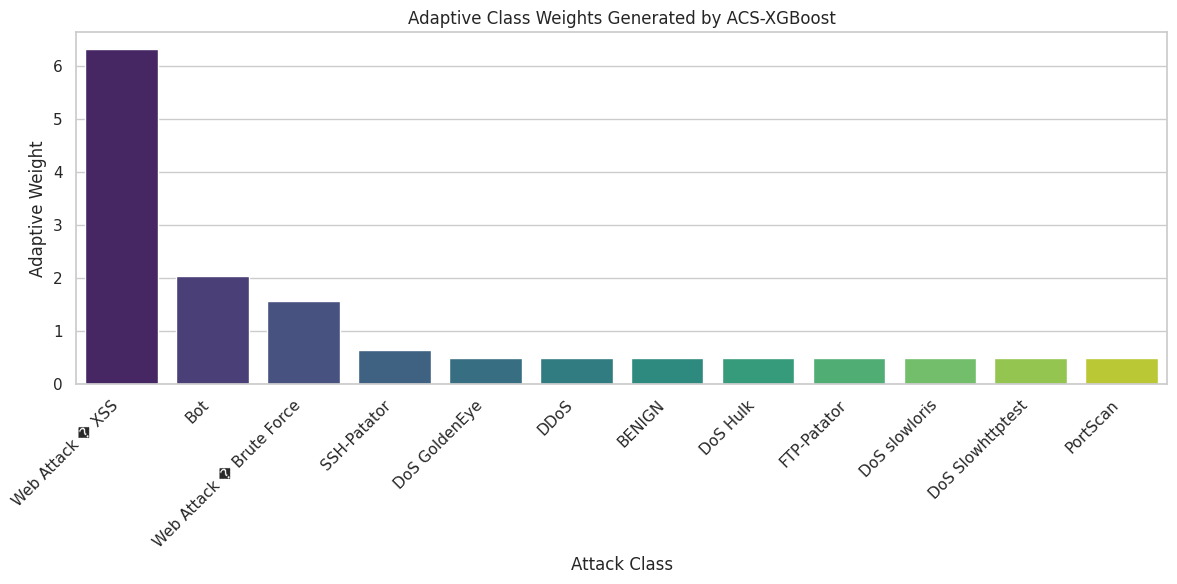

,Class,Samples,Recall,Adaptive Weight
11,Web Attack � XSS,391,0.0385,6.3123
1,Bot,1172,0.6966,2.0478
10,Web Attack � Brute Force,882,0.9489,1.5659
9,SSH-Patator,1931,0.9974,0.6462
3,DoS GoldenEye,6172,0.9976,0.5000
2,DDoS,76810,0.9993,0.5000
0,BENIGN,1257890,0.9994,0.5000
4,DoS Hulk,103709,0.9992,0.5000
7,FTP-Patator,3560,0.9986,0.5000
6,DoS slowloris,3231,0.9954,0.5000


In [30]:
plt.figure(figsize=(12,6))
plot_df = weights_df.sort_values("Adaptive Weight", ascending=False)
sns.barplot(data=plot_df, x="Class", y="Adaptive Weight", palette="viridis")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Adaptive Weight")
plt.xlabel("Attack Class")
plt.title("Adaptive Class Weights Generated by ACS-XGBoost")
plt.tight_layout()
plt.savefig("final_model/plots/adaptive_weight_distribution.png", dpi=150)
plt.show()

plot_df[["Class", "Samples", "Recall", "Adaptive Weight"]]

**What the weights say:** XSS (6.3), Bot (2.0) and Web Attack Brute Force (1.6) get boosted, which matches the
classes that are both rare and hard. Eight of the twelve classes land on the 0.5 floor, so after clipping they
are treated identically; the method is effectively separating "the three hardest rare classes" from everything
else rather than producing a smooth ranking of all twelve.

### 3.5 Bayesian hyperparameter search (Optuna)

50 trials of Optuna's default TPE sampler, maximising **validation macro F1**. Each trial trains an XGBoost
with the adaptive sample weights and early stopping.

In [31]:
N_TRIALS = 50
print(f"Number of Optuna Trials : {N_TRIALS}")
print("Evaluation Metric       : Macro F1 Score")


def objective(trial):
    params = {
        "objective": "multi:softprob",
        "num_class": len(le.classes_),
        "eval_metric": "mlogloss",
        "random_state": RANDOM_STATE,
        "device": XGB_DEVICE,
        "verbosity": 0,
        "early_stopping_rounds": 50,
        "n_estimators": trial.suggest_int("n_estimators", 200, 700),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.20, log=True),
        "subsample": trial.suggest_float("subsample", 0.60, 1.00),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.60, 1.00),
        "gamma": trial.suggest_float("gamma", 0.0, 5.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "reg_alpha": trial.suggest_float("reg_alpha", 0.0, 5.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.50, 10.00),
    }

    model = xgb.XGBClassifier(**params)
    model.fit(X_train, y_train, sample_weight=sample_weights,
              eval_set=[(X_val, y_val)], verbose=False)

    macro_f1 = f1_score(y_val, model.predict(X_val), average="macro", zero_division=0)
    del model
    gc.collect()
    return macro_f1


study = optuna.create_study(direction="maximize", study_name="ACS_XGBoost")
t0 = time.time()
study.optimize(objective, n_trials=N_TRIALS)
print(f"\nExecution Time : {(time.time() - t0) / 60:.2f} minutes")

Number of Optuna Trials : 50
Evaluation Metric       : Macro F1 Score


Execution Time : 42.81 minutes


Best Validation Macro F1 : 0.91760

n_estimators             : 604
max_depth                : 9
learning_rate            : 0.07689863330100788
subsample                : 0.9125036038487808
colsample_bytree         : 0.7790765915610146
gamma                    : 0.08174970815031654
min_child_weight         : 4
reg_alpha                : 1.3346223898540648
reg_lambda               : 3.7776858681547507


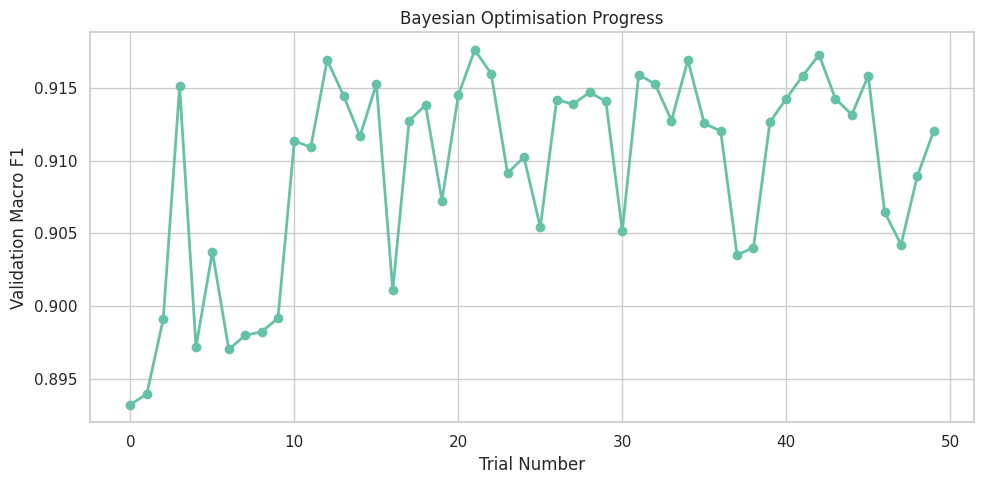

In [32]:
best_params = study.best_params
print(f"Best Validation Macro F1 : {study.best_value:.5f}\n")
for name, value in best_params.items():
    print(f"{name:<25}: {value}")

joblib.dump(study, "final_model/optuna_study.pkl")
joblib.dump(best_params, "final_model/best_xgb_parameters.pkl")
trial_history = study.trials_dataframe()
trial_history.to_csv("final_model/tables/optuna_trials.csv", index=False)

plt.figure(figsize=(10,5))
plt.plot(trial_history["number"], trial_history["value"], marker="o", linewidth=2)
plt.xlabel("Trial Number")
plt.ylabel("Validation Macro F1")
plt.title("Bayesian Optimisation Progress")
plt.grid(True)
plt.tight_layout()
plt.savefig("final_model/plots/optuna_progress.png", dpi=300)
plt.show()

### 3.6 Final ACS-XGBoost

Best hyperparameters + adaptive sample weights + early stopping on the validation set (the same early-stopping
regime every Optuna trial used). The search stopped around 450 of at most 604 trees.

In [33]:
final_params = best_params.copy()
final_params.update({
    "objective": "multi:softprob",
    "num_class": len(le.classes_),
    "eval_metric": "mlogloss",
    "random_state": RANDOM_STATE,
    "device": XGB_DEVICE,
    "verbosity": 0,
    # best_params only has the searched hyperparameters; early stopping was held fixed, so add it back
    "early_stopping_rounds": 50,
})

acs_model = xgb.XGBClassifier(**final_params)

t0 = time.time()
acs_model.fit(X_train, y_train, sample_weight=sample_weights,
              eval_set=[(X_val, y_val)], verbose=100)
training_time = time.time() - t0
print(f"\nTraining Time : {training_time:.2f} seconds")

[0]	validation_0-mlogloss:0.49722
[100]	validation_0-mlogloss:0.00448
[200]	validation_0-mlogloss:0.00388
[300]	validation_0-mlogloss:0.00383
[400]	validation_0-mlogloss:0.00382
[453]	validation_0-mlogloss:0.00382

Training Time : 52.24 seconds


### 3.7 Test-set evaluation

  ACS-XGBoost — Test Set Results
  Accuracy           : 99.8698%
  Precision (micro)  : 99.8698%
  Recall (micro)     : 99.8698%
  Balanced Accuracy  : 93.3393%
  Macro Precision    : 90.9441%
  Macro Recall       : 93.3393%
  Macro F1           : 91.5070%   <- PRIMARY METRIC
  Weighted F1        : 99.8737%
  MCC                : 0.9957
  Cohen Kappa        : 0.9957
  Train Time         : 52.24 sec
  Validation Time    : 1.5002 sec
  Inference Time     : 1.3563 sec
  RAM Usage          : 13770 MB
  VRAM Usage         : 1145 MB

=== ACS-XGBoost — Per-Class Classification Report ===
                          precision    recall  f1-score   support

                  BENIGN     0.9999    0.9990    0.9995    419297
                     Bot     0.7220    0.9565    0.8229       391
                    DDoS     0.9999    0.9998    0.9999     25603
           DoS GoldenEye     0.9961    0.9937    0.9949      2057
                DoS Hulk     0.9980    0.9998    0.9989     34570
        DoS Slo

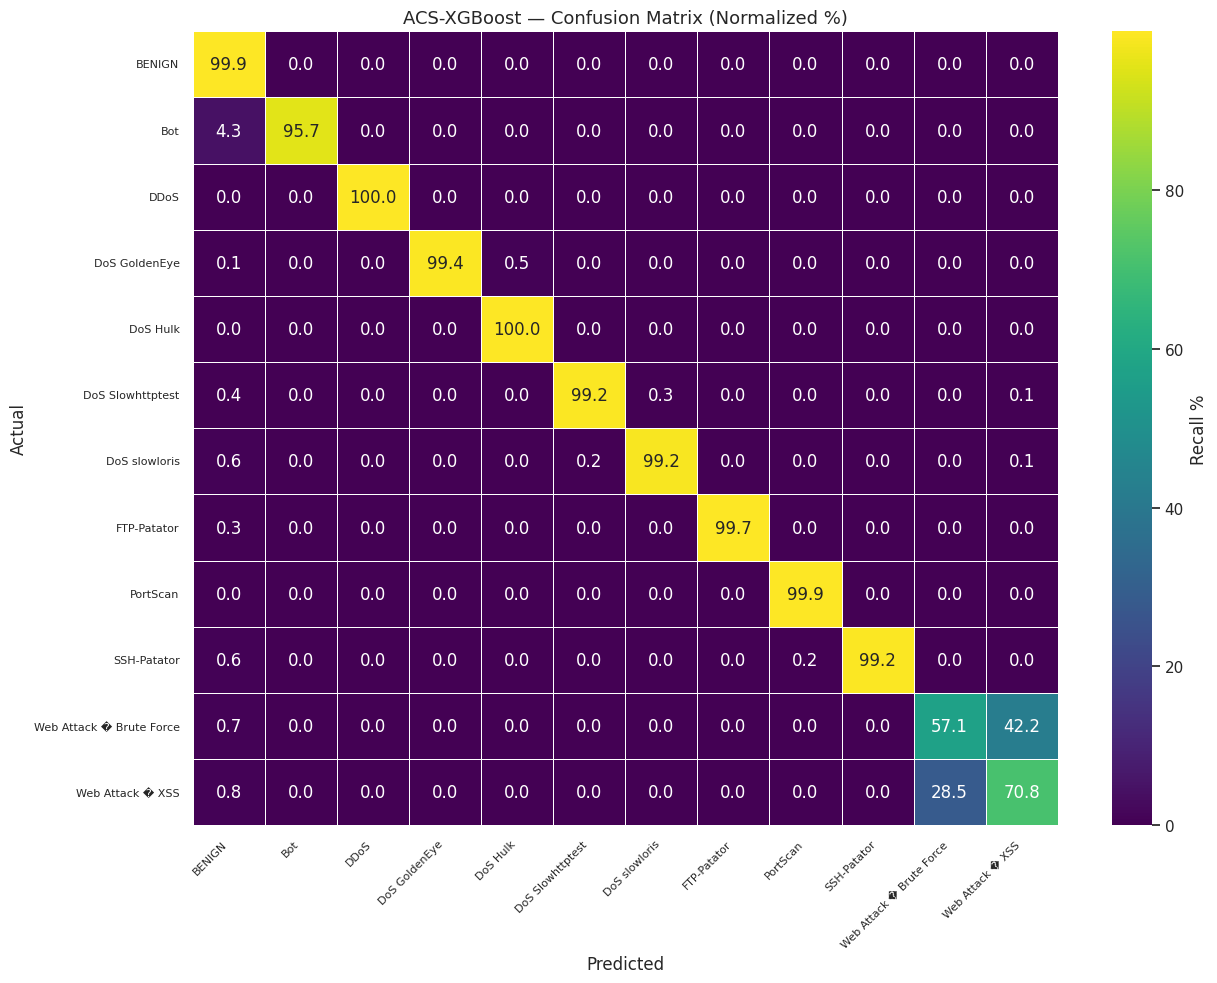

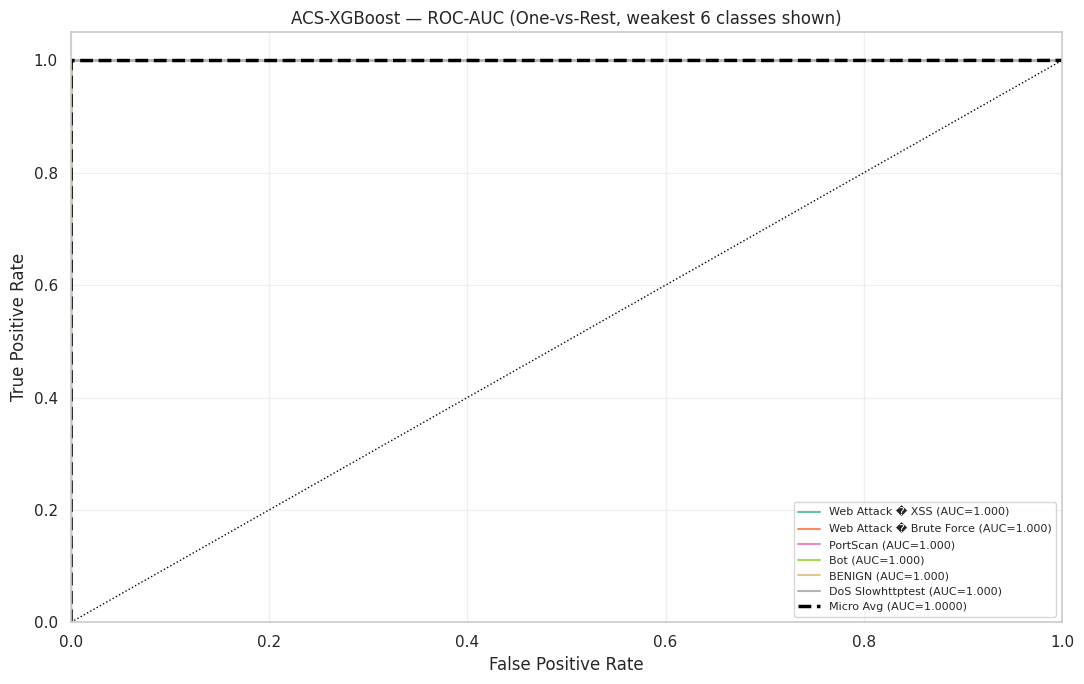

  Micro ROC-AUC : 1.0000   Macro ROC-AUC : 1.0000


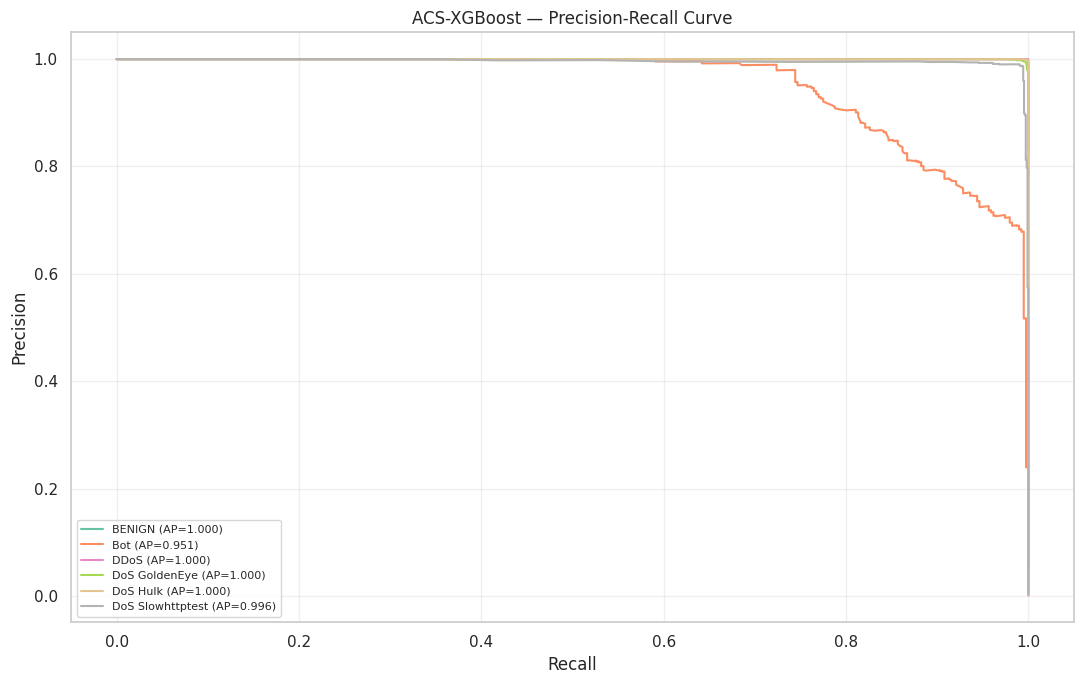

In [34]:
classes_present = sorted(y_test.unique())

acs_results, y_pred_acs, y_score_acs = full_evaluation(
    model=acs_model, model_name="ACS-XGBoost",
    X_val_set=X_val, y_val_set=y_val, X_te=X_test, y_te=y_test,
    train_time=training_time, le=le, classes_present=classes_present, cmap="viridis")

Most classes are above 99% F1. The weak spots are the same ones every model struggles with: **Web Attack XSS**
(F1 0.52) and **Web Attack Brute Force** (F1 0.67). In the confusion matrix above the two web-attack classes
are mostly confused with *each other* (42.2% of Brute Force flows predicted as XSS, 28.5% the other way), not with
benign traffic, which suggests their flow-level features are genuinely very similar.

### 3.8 Explainability with SHAP

SHAP values are computed on a random sample of 1,000 test rows to keep the cost down.

In [35]:
SHAP_SAMPLE = 1000
X_shap = X_test.sample(min(SHAP_SAMPLE, len(X_test)), random_state=RANDOM_STATE)
print(f"SHAP Sample Size : {len(X_shap):,}")

explainer = shap.TreeExplainer(acs_model)
print("\nComputing SHAP values...")
shap_values = explainer.shap_values(X_shap)
print("Completed.")


def get_class_shap_values(shap_vals, class_index):
    """Different shap versions return a list of arrays or one 3-D array; handle both."""
    if isinstance(shap_vals, list):
        return shap_vals[class_index]
    arr = np.asarray(shap_vals)
    if arr.ndim == 3:
        return arr[:, :, class_index]
    return arr

SHAP Sample Size : 1,000

Computing SHAP values...
Completed.


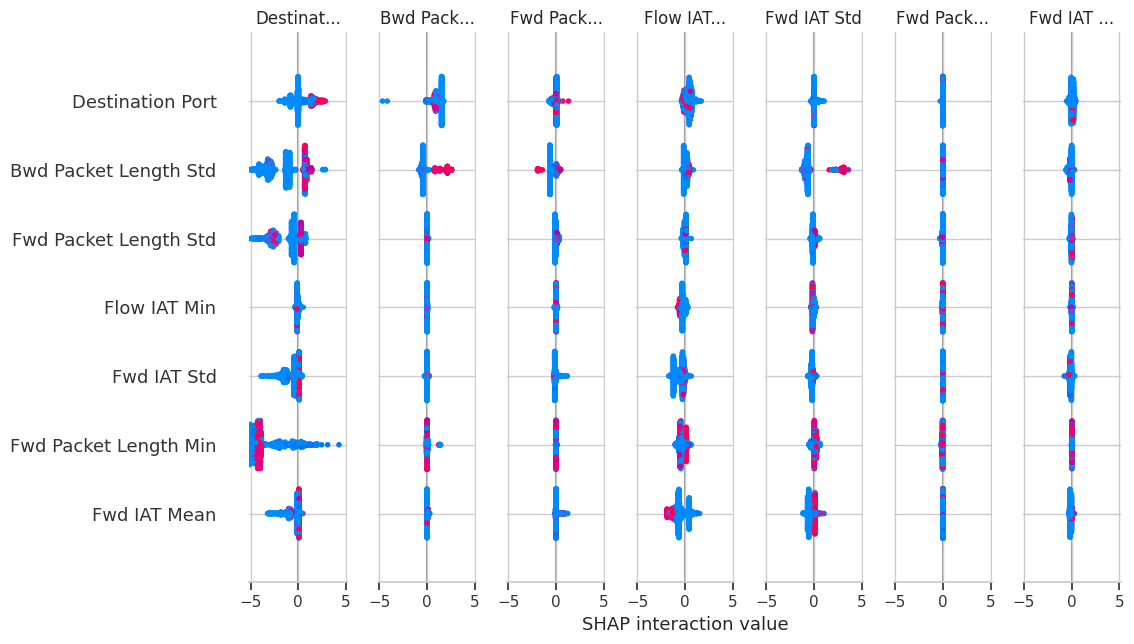

In [36]:
plt.figure(figsize=(10,8))
shap.summary_plot(shap_values, X_shap, show=False)
plt.tight_layout()
plt.savefig("final_model/plots/shap_summary.png", dpi=300, bbox_inches="tight")
plt.show()

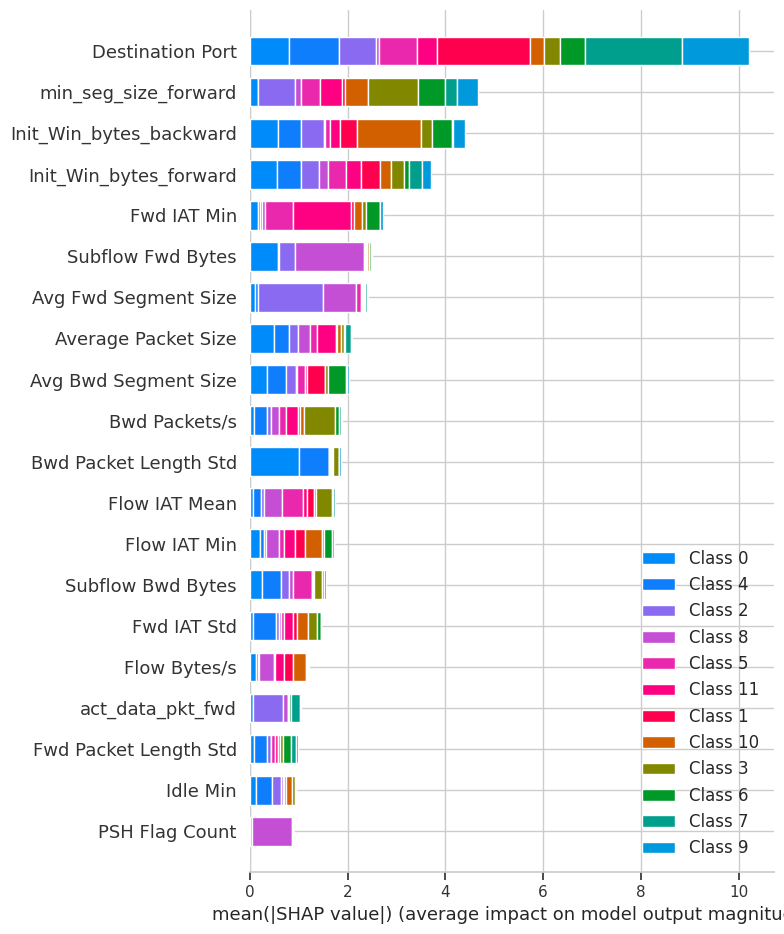

,Feature,Mean |SHAP|
0,Destination Port,0.8512
41,min_seg_size_forward,0.3882
39,Init_Win_bytes_backward,0.3670
38,Init_Win_bytes_forward,0.3079
12,Fwd IAT Min,0.2266
36,Subflow Fwd Bytes,0.2081
33,Avg Fwd Segment Size,0.2012
32,Average Packet Size,0.1735
34,Avg Bwd Segment Size,0.1683
20,Bwd Packets/s,0.1568


In [37]:
plt.figure(figsize=(10,8))
shap.summary_plot(shap_values, X_shap, plot_type="bar", show=False)
plt.tight_layout()
plt.savefig("final_model/plots/shap_feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

# mean |SHAP| per feature, averaged over samples and classes
if isinstance(shap_values, list):
    importance = np.mean(np.abs(np.stack(shap_values)), axis=(0, 1))
else:
    arr = np.array(shap_values)
    importance = np.mean(np.abs(arr), axis=(0, 2)) if arr.ndim == 3 else np.mean(np.abs(arr), axis=0)

shap_importance = pd.DataFrame({"Feature": X_shap.columns, "Mean |SHAP|": importance})
shap_importance = shap_importance.sort_values("Mean |SHAP|", ascending=False)
shap_importance.to_csv("final_model/tables/shap_feature_importance.csv", index=False)
shap_importance.head(20)

**Destination Port** is the most influential feature, at more than twice the mean |SHAP| of the next one
(0.85 vs 0.39). That makes sense for attacks tied to a service
(SSH/FTP brute force, web attacks on port 80, port scans), but it also hints at a caveat worth knowing: a model
leaning this heavily on the port may pick up dataset-specific patterns that would not carry over to other
networks.

The two plots below look at how the top feature affects the class the model predicts most often in the sample.

Top Feature : Destination Port
Using class index : 0
Class name         : BENIGN


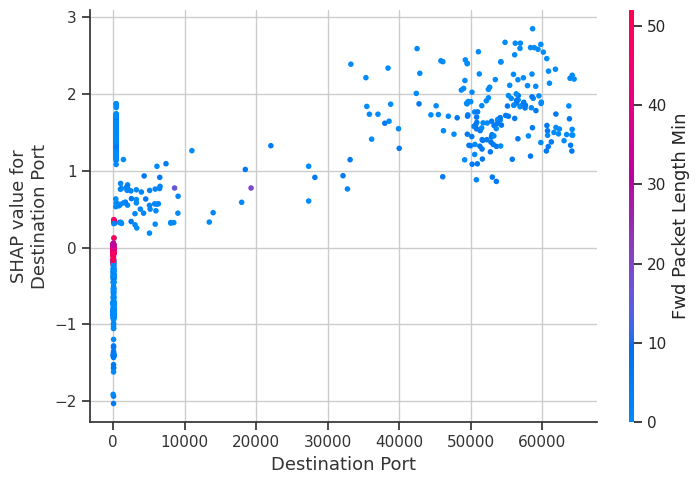

In [38]:
top_feature = shap_importance.iloc[0]["Feature"]
print(f"Top Feature : {top_feature}")

# use the class the model predicts most often in the sample, not an arbitrary fixed index
shap_preds = acs_model.predict(X_shap)
class_index = np.bincount(shap_preds).argmax()
print(f"Using class index : {class_index}")
print(f"Class name         : {le.inverse_transform([class_index])[0]}")

shap.dependence_plot(top_feature, get_class_shap_values(shap_values, class_index), X_shap, show=False)
plt.tight_layout()
plt.savefig("final_model/plots/shap_dependence.png", dpi=300, bbox_inches="tight")
plt.show()

Using 500 samples
Using class index : 0
Class Name        : BENIGN
Top Feature : Destination Port


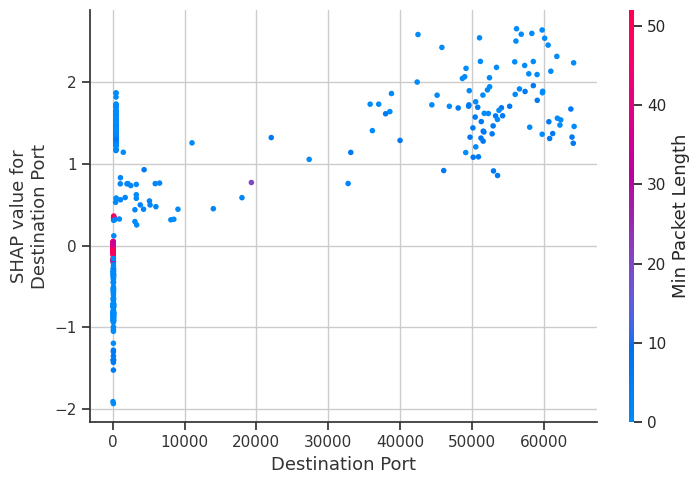

In [39]:
# Full SHAP interaction values are O(features^2) per row and too slow here, so use
# dependence_plot's automatic interaction colouring on a smaller 500-row sample instead.
X_interaction = X_test.sample(min(500, len(X_test)), random_state=RANDOM_STATE)
print(f"Using {len(X_interaction)} samples")

interaction_shap = explainer.shap_values(X_interaction)
class_index = np.bincount(acs_model.predict(X_interaction)).argmax()
print(f"Using class index : {class_index}")
print(f"Class Name        : {le.inverse_transform([class_index])[0]}")
print(f"Top Feature : {top_feature}")

shap.dependence_plot(top_feature, get_class_shap_values(interaction_shap, class_index),
                     X_interaction, interaction_index="auto", show=False)
plt.tight_layout()
plt.savefig("final_model/plots/shap_interaction.png", dpi=300, bbox_inches="tight")
plt.show()

### 3.9 Save the model and build the six-model comparison

In [40]:
joblib.dump(acs_model, "final_model/acs_xgboost.pkl")
joblib.dump({"predictions": y_pred_acs, "probabilities": y_score_acs}, "final_model/acs_predictions.pkl")

baseline_results = pd.read_csv("final_model/baseline_results.csv")
final_results = pd.concat([baseline_results, pd.DataFrame([acs_results])], ignore_index=True)
final_results.to_csv("final_model/final_model_comparison.csv", index=False)

final_results.sort_values("Macro F1", ascending=False)[show_cols]

,Model,Accuracy,Balanced Accuracy,Macro F1,MCC,Macro ROC-AUC,Train Time (s)
1,ACS-XGBoost,99.8698,93.3393,91.5070,0.9957,1.0000,52.2400
0,LightGBM,99.7157,89.3132,86.1290,0.9906,0.9134,115.5200


On the single held-out test set the ranking by macro F1 is V4 (91.63) > **ACS-XGBoost (91.51)** > V3 > V1 >
V2 > LightGBM. Per-class, ACS-XGBoost has the best F1 on Bot (0.82) and XSS (0.52), but the worst of the XGBoost
variants on Brute Force (0.67 vs 0.72 to 0.75), so the gain on the hardest class is partly paid for on its
neighbour. A single split cannot tell us whether a 0.1-point gap to V4 means anything, which is what the next
section checks.

---
## 4. Robustness checks

A single train/test split can flatter or punish a model by luck, so this section re-trains ACS-XGBoost from
scratch several ways:

1. **5-fold stratified cross-validation** on train + validation (2,017,835 rows). The adaptive weights are
   recomputed inside every fold, using only that fold's training data.
2. **Learning curve:** performance at 20 / 40 / 60 / 80 / 100% of the training data.
3. **Paired comparison with plain XGBoost** (same Optuna hyperparameters, no sample weights) on the same
   folds, with a Wilcoxon signed-rank test.

> **Caveat:** the Optuna search used the validation split, which is part of the CV data here, so the
> hyperparameters are slightly tuned to data the CV folds also see. That favours both models equally, but the
> CV scores should be read as "approximately right", not as a clean external estimate.

In [41]:
X_dev = pd.concat([X_train, X_val], axis=0, ignore_index=True)
y_dev = pd.concat([y_train, y_val], axis=0, ignore_index=True)
print(f"Development Samples : {len(X_dev):,}")
print(f"Features            : {X_dev.shape[1]}")

best_params = joblib.load("final_model/best_xgb_parameters.pkl")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Development Samples : 2,017,835
Features            : 48


The weight recipe from section 3, wrapped in a function so it can be repeated per fold. It only ever sees the
training data it is handed: the difficulty probe uses its own inner 80/20 split, and the held-out fold is
never passed in.

In [42]:
def compute_adaptive_weights(X_tr, y_tr, alpha=0.5, w_min=0.50, w_max=10.00, inner_val_size=0.2):
    # inner split, used only to measure per-class difficulty
    X_in_tr, X_in_val, y_in_tr, y_in_val = train_test_split(
        X_tr, y_tr, test_size=inner_val_size, stratify=y_tr, random_state=RANDOM_STATE)

    probe = make_prelim_model()
    probe.fit(X_in_tr, y_in_tr, verbose=False)
    y_hat = probe.predict(X_in_val)

    classes = np.unique(y_tr)
    N, K = len(y_tr), len(classes)

    # recall_score(average=None) returns one value per label, in the order of `classes`
    recalls = recall_score(y_in_val, y_hat, average=None, labels=classes, zero_division=0)

    freq_w = np.array([N / (K * np.sum(y_tr == c)) for c in classes], dtype=float)
    diff_w = 1 + (1 - recalls)

    freq_norm = (freq_w - freq_w.min()) / (freq_w.max() - freq_w.min() + 1e-12)
    diff_norm = (diff_w - diff_w.min()) / (diff_w.max() - diff_w.min() + 1e-12)

    combined = alpha * freq_norm + (1 - alpha) * diff_norm
    combined = combined / combined.mean()
    combined = np.clip(combined, w_min, w_max)

    weight_dict = dict(zip(classes, combined))
    sample_weights = np.array([weight_dict[label] for label in y_tr])

    del probe
    gc.collect()
    return weight_dict, sample_weights


def cv_params():
    p = best_params.copy()
    p.update({"objective": "multi:softprob", "num_class": len(le.classes_), "eval_metric": "mlogloss",
              "random_state": RANDOM_STATE, "device": XGB_DEVICE, "verbosity": 0})
    return p

### 4.1 5-fold CV: ACS-XGBoost

In [43]:
cv_results = []

for fold, (train_idx, valid_idx) in enumerate(cv.split(X_dev, y_dev), start=1):
    print(f"\nFold {fold}/5")

    X_tr, X_va = X_dev.iloc[train_idx], X_dev.iloc[valid_idx]
    y_tr, y_va = y_dev.iloc[train_idx], y_dev.iloc[valid_idx]

    # weights come from the fold's training data only
    _, fold_weights = compute_adaptive_weights(X_tr, y_tr)

    model = xgb.XGBClassifier(**cv_params())
    t0 = time.time()
    model.fit(X_tr, y_tr, sample_weight=fold_weights, verbose=False)
    train_time = time.time() - t0

    y_pred = model.predict(X_va)
    result = {
        "Fold": fold,
        "Accuracy": accuracy_score(y_va, y_pred),
        "Precision": precision_score(y_va, y_pred, average="macro", zero_division=0),
        "Recall": recall_score(y_va, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_va, y_pred, average="macro", zero_division=0),
        "Weighted F1": f1_score(y_va, y_pred, average="weighted", zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_va, y_pred),
        "MCC": matthews_corrcoef(y_va, y_pred),
        "Kappa": cohen_kappa_score(y_va, y_pred),
        "Training Time": train_time,
    }
    cv_results.append(result)
    print(f"Accuracy : {result['Accuracy']:.4f}")
    print(f"Macro F1 : {result['Macro F1']:.4f}")
    print(f"MCC      : {result['MCC']:.4f}")

    del model
    gc.collect()

print("\nCross Validation Completed.")

Fold 1/5
Accuracy : 0.9986
Macro F1 : 0.9190
MCC      : 0.9955

Fold 2/5
Accuracy : 0.9986
Macro F1 : 0.9111
MCC      : 0.9955

Fold 3/5
Accuracy : 0.9988
Macro F1 : 0.9090
MCC      : 0.9960

Fold 4/5
Accuracy : 0.9987
Macro F1 : 0.9148
MCC      : 0.9957

Fold 5/5
Accuracy : 0.9986
Macro F1 : 0.9054
MCC      : 0.9955

Cross Validation Completed.


,Fold,Accuracy,Precision,Recall,Macro F1,Weighted F1,Balanced Accuracy,MCC,Kappa,Training Time
0,1,0.9986,0.9115,0.9378,0.9190,0.9987,0.9378,0.9955,0.9955,65.2355
1,2,0.9986,0.9018,0.9293,0.9111,0.9987,0.9293,0.9955,0.9955,65.1328
2,3,0.9988,0.9035,0.9253,0.9090,0.9988,0.9253,0.9960,0.9960,65.2717
3,4,0.9987,0.9078,0.9314,0.9148,0.9987,0.9314,0.9957,0.9957,65.4399
4,5,0.9986,0.8990,0.9214,0.9054,0.9987,0.9214,0.9955,0.9955,65.4336


,Metric,Mean,Std,Mean ± Std
0,Accuracy,0.9987,0.0001,0.9987 ± 0.0001
1,Precision,0.9047,0.0050,0.9047 ± 0.0050
2,Recall,0.9290,0.0062,0.9290 ± 0.0062
3,Macro F1,0.9118,0.0053,0.9118 ± 0.0053
4,Weighted F1,0.9987,0.0001,0.9987 ± 0.0001
5,Balanced Accuracy,0.9290,0.0062,0.9290 ± 0.0062
6,MCC,0.9956,0.0002,0.9956 ± 0.0002
7,Kappa,0.9956,0.0002,0.9956 ± 0.0002
8,Training Time,65.3027,0.1326,65.3027 ± 0.1326


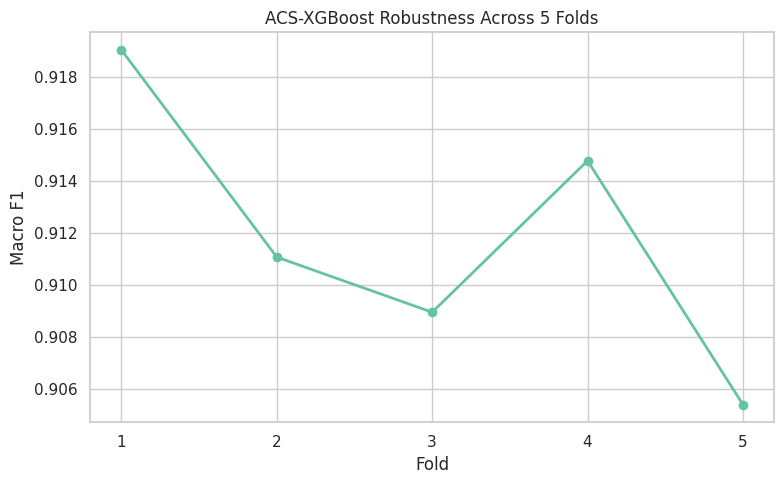

In [44]:
cv_results = pd.DataFrame(cv_results)
display(cv_results)

summary = pd.DataFrame({
    "Metric": cv_results.columns[1:],
    "Mean": cv_results.iloc[:, 1:].mean().values,
    "Std": cv_results.iloc[:, 1:].std().values,
})
summary["Mean ± Std"] = summary.apply(lambda r: f"{r['Mean']:.4f} ± {r['Std']:.4f}", axis=1)
display(summary)

summary.to_csv("final_model/tables/acs_cv_summary.csv", index=False)
cv_results.to_csv("final_model/tables/acs_cv_results.csv", index=False)

plt.figure(figsize=(8,5))
plt.plot(cv_results["Fold"], cv_results["Macro F1"], marker="o", linewidth=2)
plt.xticks([1, 2, 3, 4, 5])
plt.xlabel("Fold")
plt.ylabel("Macro F1")
plt.title("ACS-XGBoost Robustness Across 5 Folds")
plt.grid(True)
plt.tight_layout()
plt.savefig("final_model/plots/acs_cv_macro_f1.png", dpi=300)
plt.show()

Macro F1 stays in a narrow band across folds (about 0.905 to 0.919), so the method is stable, with fold-to-fold
variation of roughly half a point.

### 4.2 Learning curve

Retrain on 20% to 100% of the training split (adaptive weights recomputed each time) and score on the
validation split.

Training Size : 20%
Samples : 302,675
Macro F1          : 0.9150
Balanced Accuracy : 0.9261
Training Time     : 16.21 sec

Training Size : 40%
Samples : 605,350
Macro F1          : 0.9108
Balanced Accuracy : 0.9227
Training Time     : 27.60 sec

Training Size : 60%
Samples : 908,025
Macro F1          : 0.9148
Balanced Accuracy : 0.9299
Training Time     : 38.74 sec

Training Size : 80%
Samples : 1,210,700
Macro F1          : 0.9231
Balanced Accuracy : 0.9403
Training Time     : 50.05 sec

Training Size : 100%
Samples : 1,513,376
Macro F1          : 0.9159
Balanced Accuracy : 0.9327
Training Time     : 61.48 sec


,Training Size,Macro F1,Balanced Accuracy,Training Time
0,302675,0.9150,0.9261,16.2054
1,605350,0.9108,0.9227,27.6007
2,908025,0.9148,0.9299,38.7446
3,1210700,0.9231,0.9403,50.0547
4,1513376,0.9159,0.9327,61.4849


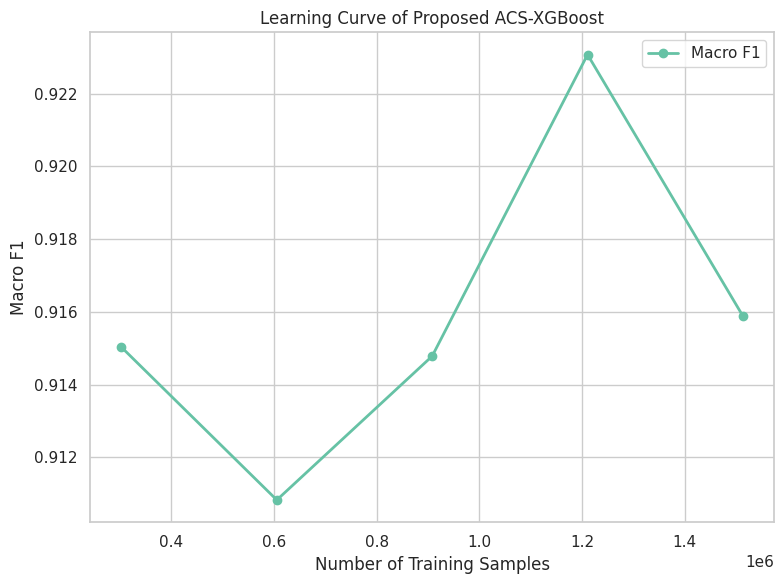

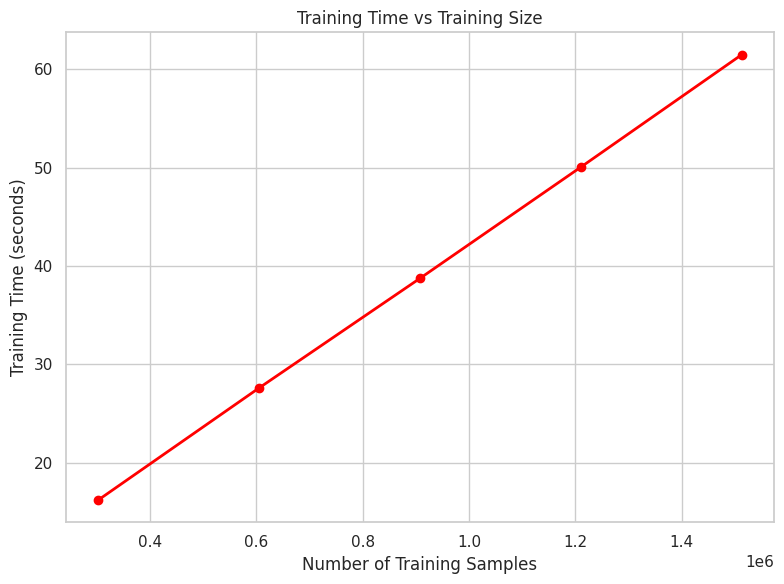

In [45]:
training_sizes = [0.2, 0.4, 0.6, 0.8, 1.0]
learning_results = []

for frac in training_sizes:
    print(f"\nTraining Size : {int(frac * 100)}%")

    if frac < 1.0:
        splitter = StratifiedShuffleSplit(n_splits=1, train_size=frac, random_state=RANDOM_STATE)
        subset_idx, _ = next(splitter.split(X_train, y_train))
        X_sub = X_train.iloc[subset_idx].reset_index(drop=True)
        y_sub = y_train.iloc[subset_idx].reset_index(drop=True)
    else:
        X_sub = X_train.copy().reset_index(drop=True)
        y_sub = y_train.copy().reset_index(drop=True)
    print(f"Samples : {len(X_sub):,}")

    _, sub_weights = compute_adaptive_weights(X_sub, y_sub)

    model = xgb.XGBClassifier(**cv_params())
    t0 = time.time()
    model.fit(X_sub, y_sub, sample_weight=sub_weights, verbose=False)
    train_time = time.time() - t0

    y_pred = model.predict(X_val)
    macro_f1 = f1_score(y_val, y_pred, average="macro", zero_division=0)
    bal_acc = balanced_accuracy_score(y_val, y_pred)
    learning_results.append({"Training Size": len(X_sub), "Macro F1": macro_f1,
                             "Balanced Accuracy": bal_acc, "Training Time": train_time})

    print(f"Macro F1          : {macro_f1:.4f}")
    print(f"Balanced Accuracy : {bal_acc:.4f}")
    print(f"Training Time     : {train_time:.2f} sec")

    del model
    gc.collect()

learning_results = pd.DataFrame(learning_results)
display(learning_results)
learning_results.to_csv("final_model/tables/acs_learning_curve.csv", index=False)

plt.figure(figsize=(8,6))
plt.plot(learning_results["Training Size"], learning_results["Macro F1"], marker="o", linewidth=2, label="Macro F1")
plt.xlabel("Number of Training Samples")
plt.ylabel("Macro F1")
plt.title("Learning Curve of Proposed ACS-XGBoost")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("final_model/plots/acs_learning_curve.png", dpi=300)
plt.show()

plt.figure(figsize=(8,6))
plt.plot(learning_results["Training Size"], learning_results["Training Time"], marker="o", linewidth=2, color="red")
plt.xlabel("Number of Training Samples")
plt.ylabel("Training Time (seconds)")
plt.title("Training Time vs Training Size")
plt.grid(True)
plt.tight_layout()
plt.savefig("final_model/plots/acs_training_time_curve.png", dpi=300)
plt.show()

Macro F1 stays within about a point of 0.915 from 20% of the data to 100%, while training time grows roughly
linearly (16 s to 61 s). That suggests that simply adding more data of the same kind would not help much; the
remaining errors sit in a few classes (XSS, Brute Force, Bot) that overlap in feature space or have only a few
hundred examples in total. The bump at 80% is within the fold-to-fold noise seen above.

### 4.3 Baseline XGBoost, same folds

Same Optuna hyperparameters, same five folds, but **no sample weights**. This isolates the effect of the
adaptive weighting.

In [46]:
baseline_cv = []

for fold, (train_idx, valid_idx) in enumerate(cv.split(X_dev, y_dev), start=1):
    print(f"\nFold {fold}/5")

    X_tr, X_va = X_dev.iloc[train_idx], X_dev.iloc[valid_idx]
    y_tr, y_va = y_dev.iloc[train_idx], y_dev.iloc[valid_idx]

    model = xgb.XGBClassifier(**cv_params())
    t0 = time.time()
    model.fit(X_tr, y_tr, verbose=False)
    train_time = time.time() - t0

    y_pred = model.predict(X_va)
    baseline_cv.append({
        "Fold": fold,
        "Accuracy": accuracy_score(y_va, y_pred),
        "Macro F1": f1_score(y_va, y_pred, average="macro", zero_division=0),
        "Balanced Accuracy": balanced_accuracy_score(y_va, y_pred),
        "MCC": matthews_corrcoef(y_va, y_pred),
        "Training Time": train_time,
    })
    print(f"Macro F1 : {baseline_cv[-1]['Macro F1']:.4f}")

baseline_cv = pd.DataFrame(baseline_cv)
display(baseline_cv)
baseline_cv.to_csv("final_model/tables/baseline_xgb_cv.csv", index=False)

Fold 1/5
Macro F1 : 0.9151

Fold 2/5
Macro F1 : 0.9120

Fold 3/5
Macro F1 : 0.9127

Fold 4/5
Macro F1 : 0.9227

Fold 5/5
Macro F1 : 0.9103


,Fold,Accuracy,Macro F1,Balanced Accuracy,MCC,Training Time
0,1,0.9988,0.9151,0.9114,0.9960,65.9228
1,2,0.9988,0.9120,0.9070,0.9960,66.2920
2,3,0.9989,0.9127,0.9061,0.9965,66.0860
3,4,0.9989,0.9227,0.9163,0.9963,66.6143
4,5,0.9989,0.9103,0.9045,0.9962,66.1552


### 4.4 Wilcoxon signed-rank test

One-sided test of whether ACS-XGBoost's per-fold macro F1 is *greater* than the baseline's.

Only 5 paired observations are available, so the smallest p-value this test can possibly return is about
0.031. It is a sanity check, not strong evidence either way.

Statistic : 12.0000
P-value   : 0.906250

No statistically significant difference was observed.


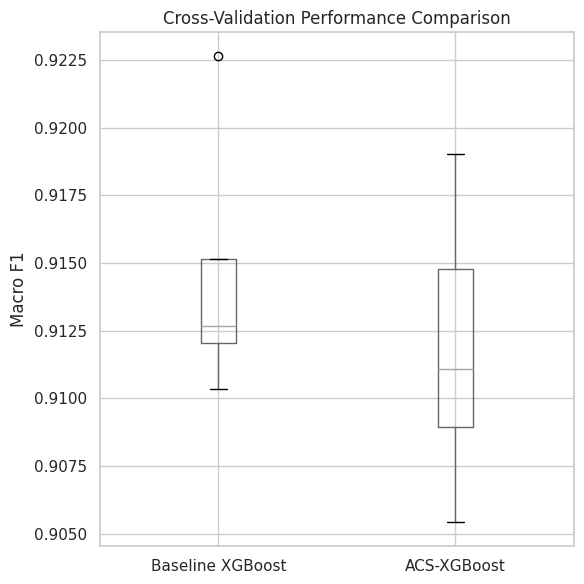

In [47]:
acs_scores = cv_results["Macro F1"]
baseline_scores = baseline_cv["Macro F1"]

stat, p_value = wilcoxon(baseline_scores, acs_scores, alternative="less")
print(f"Statistic : {stat:.4f}")
print(f"P-value   : {p_value:.6f}")

if p_value < 0.05:
    print("\nACS-XGBoost is significantly better than baseline XGBoost (p < 0.05).")
else:
    print("\nNo statistically significant difference was observed.")

pd.DataFrame({"Statistic": [stat], "P-value": [p_value]}).to_csv("final_model/tables/wilcoxon_test.csv", index=False)

pd.DataFrame({"Baseline XGBoost": baseline_scores, "ACS-XGBoost": acs_scores}).boxplot()
plt.ylabel("Macro F1")
plt.title("Cross-Validation Performance Comparison")
plt.grid(True)
plt.tight_layout()
plt.savefig("final_model/plots/wilcoxon_boxplot.png", dpi=300)
plt.show()

---
## 5. Takeaways and limitations

**What the results support**

- Class weighting matters far more than model family for this problem: every weighted XGBoost variant beats
  LightGBM by roughly 4 to 5.5 points of macro F1, and all of them reach >99.8% accuracy.
- ACS-XGBoost produces competitive weights **automatically**. On the test set it matches the best hand-tuned
  weighting to within about 0.1 macro-F1 points (91.51 vs 91.63) with no manual tuning of per-class boosts, and
  it has the best F1 on the two rarest-and-hardest classes it targets (Bot and XSS).
- It is stable: CV macro F1 is 0.912 ± 0.005 across five folds, and the learning curve is nearly flat from 20% of the data.
- SMOTE was the most expensive option (about 8x the training time) and did not pay off.

**What the results do *not* support**

- **ACS-XGBoost is not shown to beat plain XGBoost.** In cross-validation the baseline averages 0.9146 macro F1
  against 0.9118 for ACS-XGBoost, and the one-sided Wilcoxon test gives p = 0.91. The honest reading is "no
  measurable difference", not "improvement". The baseline in that test also uses hyperparameters that were
  tuned *with* the adaptive weights, which if anything favours ACS-XGBoost.
- It also does not beat hand-tuned V4 on the test set, and it trades Brute Force F1 for XSS/Bot F1.

**Limitations and things I would do next**

- With the 0.5 floor, 8 of 12 classes get identical weights. Trying a different clip range, alpha, or a
  smoother transform of the frequency term would be the first experiment.
- Optuna's sampler was not seeded, so the search is not exactly reproducible; the saved best parameters are.
- The two web-attack classes remain the bottleneck (F1 0.52 and 0.67). They need better features or
  more data, not just different weights.
- Heavy reliance on *Destination Port* (see SHAP) suggests testing on a second dataset or a time-based split
  before trusting these numbers in a different network.
- CICIDS2017's `Web Attack � ...` labels contain a broken en-dash character from the source CSVs; cleaning
  the labels would tidy the plots.